# Splitly growth analysis

Question from the board: is the viral coefficient (K) really close to 1?

Data: 5 raw CSV files, Jan 2025 to Jun 2026, extracted on 30 June 2026. Amounts in euros.

## 0. Load the raw files

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns
from pathlib import Path

DATA = Path("../data")   # folder with the csv files, change it if needed
users_raw   = pd.read_csv(DATA / "users.csv")
invites_raw = pd.read_csv(DATA / "invites.csv")
rewards_raw = pd.read_csv(DATA / "referral_rewards.csv")
spend       = pd.read_csv(DATA / "marketing_spend.csv")
ratings     = pd.read_csv(DATA / "app_store_ratings.csv")
# key dates of the case
START = pd.Timestamp("2025-01-01")           # first day of the data
END = pd.Timestamp("2026-06-30")             # extraction date
REFERRAL_START = pd.Timestamp("2025-11-01")  # double sided referral bonus starts
SYNC_START = pd.Timestamp("2026-03-01")      # contact sync and auto SMS start
sizes = {"users": users_raw, "invites": invites_raw, "rewards": rewards_raw, "spend": spend, "ratings": ratings}
for name, df in sizes.items():
    print(f"{name:10s} {df.shape[0]:>8,} rows  {df.shape[1]} columns")
users_raw.head()

users        95,784 rows  8 columns
invites     201,385 rows  6 columns
rewards      16,536 rows  5 columns
spend            18 rows  3 columns
ratings          17 rows  4 columns


,user_id,signup_date,source,inviter_user_id,country,activated,splits_first_30d,last_active_date
0,U002341,2025-01-01,paid,NaN,IT,1,2,2025-01-18
1,U000620,2025-01-01,organic,NaN,ES,1,1,2025-01-15
2,U002327,2025-01-01,paid,NaN,FR,1,3,2025-12-02
3,U000942,2025-01-01,organic,NaN,DE,0,0,2025-01-01
4,U001775,2025-01-01,paid,NaN,FR,1,3,2025-12-01


## 1. Data cleaning

First we explore the data (missing values, labels, dates), then we clean it step by step. Every rule is stored in a small list so we can print a report at the end.
### 1.1 First look: what is missing?

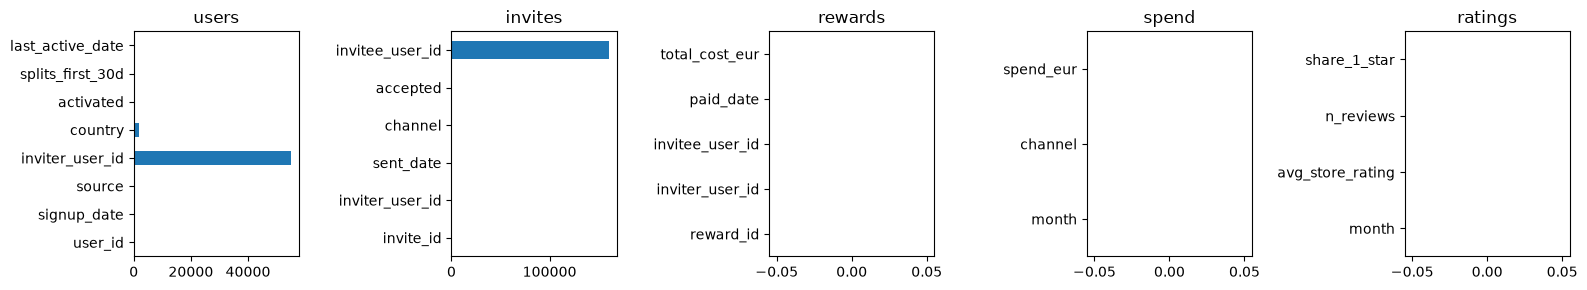

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, (name, df) in zip(axes, sizes.items()):
    df.isna().sum().plot(kind="barh", ax=ax, title=name)
plt.tight_layout()
plt.show()

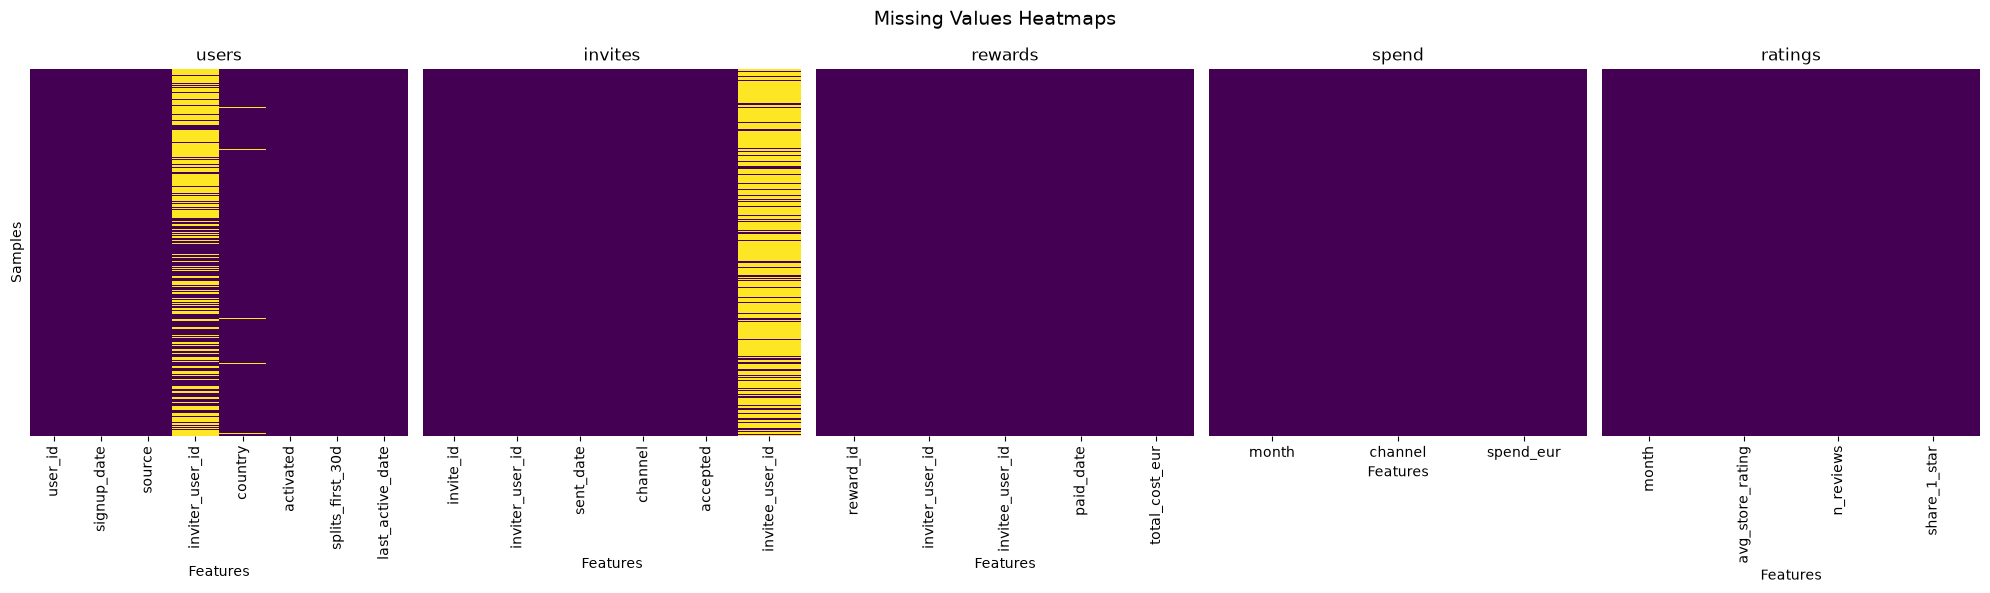

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, (name, df) in zip(axes, sizes.items()):
    sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False, xticklabels=True, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Features")
    ax.set_ylabel("Samples" if ax == axes[0] else "")

plt.suptitle("Missing Values Heatmaps", fontsize=14)
plt.tight_layout()
plt.show()   # yellow is missing data

,user_id,signup_date,inviter_user_id,country,activated,splits_first_30d,last_active_date
source,,,,,,,
internal,0.0,0.0,1.0,0.000000,0.0,0.0,0.0
invite,0.0,0.0,0.0,0.018694,0.0,0.0,0.0
organic,0.0,0.0,1.0,0.019031,0.0,0.0,0.0
paid,0.0,0.0,1.0,0.020641,0.0,0.0,0.0


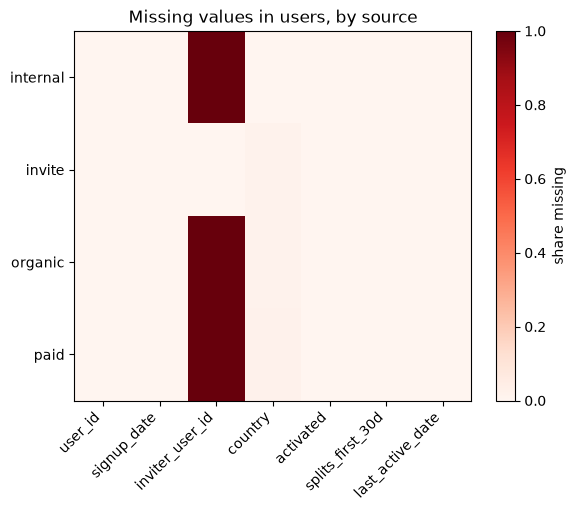

In [4]:
# do the missing values go together? share of missing values by source
miss_by_source = users_raw.drop(columns="source").isna().groupby(users_raw.source).mean()
display(miss_by_source)

plt.imshow(miss_by_source.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
plt.xticks(range(miss_by_source.shape[1]), miss_by_source.columns, rotation=45, ha="right")
plt.yticks(range(miss_by_source.shape[0]), miss_by_source.index)
plt.colorbar(label="share missing")
plt.title("Missing values in users, by source")
plt.show()

In [5]:
# in invites, invitee_user_id should be empty exactly when the invite was not accepted
display(invites_raw.isna().groupby(invites_raw.accepted).mean())

,invite_id,inviter_user_id,sent_date,channel,accepted,invitee_user_id
accepted,,,,,,
0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0


Findings: `inviter_user_id` is empty only for organic and paid users (expected). `country` is missing in every source, so it is a real data gap. `invitee_user_id` is empty only when the invite was not accepted (expected).

In [6]:
cleaning_log = []

def note(step, table, problem, action, rows):
    cleaning_log.append({"step": step, "table": table, "problem": problem, "action": action, "rows": int(rows)})

### 1.2 users: dates

In [7]:
users = users_raw.copy()
text = users["signup_date"].astype(str)
is_iso = text.str.match(r"^\d{4}-\d{2}-\d{2}$")
print("rows with a dd/mm/yyyy date:", (~is_iso).sum())
# is it day first or month first? look at the two numbers of the slash dates
print("max first number :", text[~is_iso].str[0:2].astype(int).max(), "(above 12, so it is the day)")
print("max middle number:", text[~is_iso].str[3:5].astype(int).max())
date_iso = pd.to_datetime(text.where(is_iso), format="%Y-%m-%d")
date_slash = pd.to_datetime(text.where(~is_iso), format="%d/%m/%Y")
users["signup_date"] = date_iso.fillna(date_slash)
users["last_active_date"] = pd.to_datetime(users["last_active_date"])
note("U1", "users", "signup_date mixes yyyy-mm-dd and dd/mm/yyyy", "parse each format separately", (~is_iso).sum())

rows with a dd/mm/yyyy date: 1439
max first number : 31 (above 12, so it is the day)
max middle number: 12


In [8]:
# impossible dates (placeholders like 1900, 1970, 2099)
bad_date = (users.signup_date < START) | (users.signup_date > END)
display(users.loc[bad_date, ["user_id", "signup_date", "source", "last_active_date"]])

bad_user_ids = set(users.loc[bad_date, "user_id"])
note("U2", "users", "signup_date outside the data period", "drop the user", bad_date.sum())
users = users[~bad_date]

,user_id,signup_date,source,last_active_date
17135,U015951,2099-12-31,organic,2025-06-21
28738,U026467,1900-01-01,organic,2026-05-23
31010,U031197,1970-01-01,paid,2025-12-11
34564,U036341,1900-01-01,invite,2025-11-10
36755,U040597,1970-01-01,invite,2025-11-21
57991,U055128,2099-12-31,invite,2026-02-24


### 1.3 users: test accounts and missing country

In [9]:
is_test = (users.source == "internal") | users.user_id.str.startswith("QA_")
display(users[is_test].head(3))
test_ids = set(users.loc[is_test, "user_id"])
note("U3", "users", "internal QA accounts (250 splits each)", "drop them and their invites", is_test.sum())
users = users[~is_test]

n_missing = users.country.isna().sum()
users["country"] = users["country"].fillna("Unknown")
note("U4", "users", "country is missing", "fill with Unknown, keep the row", n_missing)

,user_id,signup_date,source,inviter_user_id,country,activated,splits_first_30d,last_active_date
95772,QA_000,2025-03-20,internal,NaN,FR,1,250,2026-06-30
95773,QA_001,2025-03-20,internal,NaN,FR,1,250,2026-06-30
95774,QA_002,2025-03-20,internal,NaN,FR,1,250,2026-06-30


In [10]:
# consistency checks, 0 rows means the check passed
checks = {
    "duplicated user_id": users.user_id.duplicated().sum(),
    "last_active before signup": (users.last_active_date < users.signup_date).sum(),
    "splits_first_30d above 100": (users.splits_first_30d > 100).sum(),
    "activated does not match splits": (((users.activated == 0) & (users.splits_first_30d > 0)) |
                                        ((users.activated == 1) & (users.splits_first_30d == 0))).sum(),
    "source does not match inviter": (((users.source == "invite") & users.inviter_user_id.isna()) |
                                      ((users.source != "invite") & users.inviter_user_id.notna())).sum(),
}
for name, n in checks.items():
    note("U5", "users", name, "check only", n)

n_inviter_removed = users.inviter_user_id.isin(bad_user_ids | test_ids).sum()
note("U6", "users", "invited users whose inviter was removed", "keep the user, inviter unknown", n_inviter_removed)
print("users after cleaning:", len(users))

users after cleaning: 95766


### 1.4 invites

unparsed dates: 0
range: 2025-01-01 to 2026-06-29


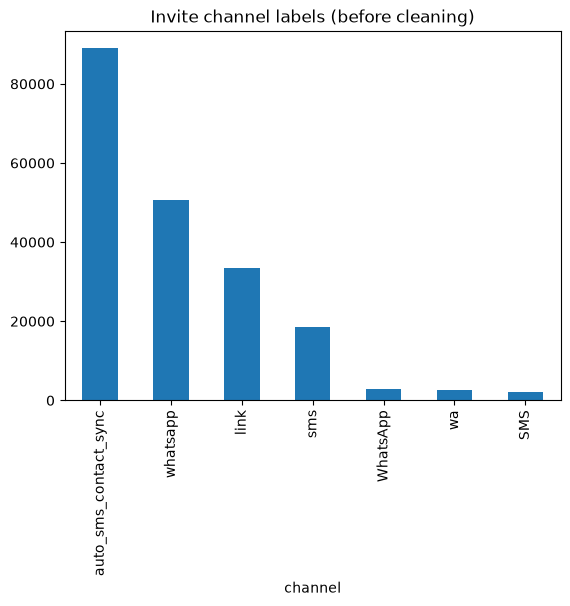

In [11]:
invites = invites_raw.copy()
invites["sent_date"] = pd.to_datetime(invites["sent_date"], errors="coerce")
print("unparsed dates:", invites.sent_date.isna().sum())
print("range:", invites.sent_date.min().date(), "to", invites.sent_date.max().date())

n_dup = invites.duplicated().sum()
invites = invites.drop_duplicates()
note("I1", "invites", "exact duplicate rows", "drop_duplicates", n_dup)
invites.channel.value_counts().plot(kind="bar", title="Invite channel labels (before cleaning)")
plt.show()

In [12]:
channel_map = {"WhatsApp": "whatsapp", "wa": "whatsapp", "SMS": "sms"}
n_labels = invites.channel.isin(channel_map.keys()).sum()
invites["channel"] = invites["channel"].replace(channel_map)
note("I2", "invites", "same channel with different labels", "map to 4 channels", n_labels)
print(invites.channel.value_counts())

channel
auto_sms_contact_sync    88971
whatsapp                 56311
link                     33423
sms                      20687
Name: count, dtype: int64


In [13]:
is_test_invite = invites.inviter_user_id.isin(test_ids)
note("I3", "invites", "invites sent by QA accounts", "drop", is_test_invite.sum())
invites = invites[~is_test_invite]

bad_invitee = invites.invitee_user_id.isin(bad_user_ids)
note("I4", "invites", "accepted invite whose invitee was removed", "drop", bad_invitee.sum())
invites = invites[~bad_invitee]

n_acc = (((invites.accepted == 1) & invites.invitee_user_id.isna()) |
         ((invites.accepted == 0) & invites.invitee_user_id.notna())).sum()
note("I5", "invites", "accepted flag does not match invitee", "check only", n_acc)
note("I6", "invites", "invite_id duplicated after I1", "check only", invites.invite_id.duplicated().sum())

June 2026 looks incomplete. Let's see the invites per day.

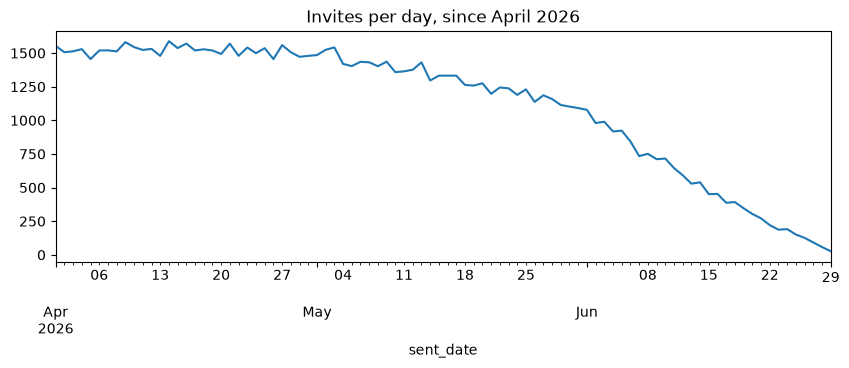

average per day in May 2026: 1309
sent_date
2026-06-25    151
2026-06-26    126
2026-06-27     92
2026-06-28     58
2026-06-29     27
dtype: int64


In [14]:
daily = invites.groupby("sent_date").size()
daily["2026-04-01":].plot(figsize=(10, 3), title="Invites per day, since April 2026")
plt.show()
print("average per day in May 2026:", round(daily["2026-05-01":"2026-05-31"].mean()))
print(daily.tail(5))

In [15]:
LAST_FULL = pd.Timestamp("2026-05-31")   # last complete month
n_june = (invites.sent_date > LAST_FULL).sum()
note("I7", "invites and users", "June 2026 is incomplete (looks like extraction lag)",
     "keep rows but exclude June from rates, trends and the model", n_june)

### 1.5 rewards, spend and ratings

In [16]:
rewards = rewards_raw.copy()
rewards["paid_date"] = pd.to_datetime(rewards["paid_date"], errors="coerce")

removed = bad_user_ids | test_ids
bad_reward = rewards.invitee_user_id.isin(removed) | rewards.inviter_user_id.isin(removed)
note("R1", "rewards", "reward linked to a removed user", "drop", bad_reward.sum())
rewards = rewards[~bad_reward]
r = rewards.merge(users[["user_id", "signup_date", "activated"]], left_on="invitee_user_id", right_on="user_id", how="left")
note("R2", "rewards", "reward paid before signup", "check only", (r.paid_date < r.signup_date).sum())
note("R3", "rewards", "duplicate invitee or cost different from 10 euros", "check only",
     rewards.invitee_user_id.duplicated().sum() + (rewards.total_cost_eur != 10).sum())

# the rule says the reward is paid at the first split, so activated should always be 1
rewards["invitee_activated"] = r.activated.values
note("R4", "rewards", "reward paid but the invitee never made a split",
     "keep (money was paid), flag it and measure the leak", (r.activated == 0).sum())

In [17]:
spend["month"] = pd.to_datetime(spend["month"])
print("channels in spend:", spend.channel.unique(), "| months:", spend.month.nunique(), "| negatives:", (spend.spend_eur < 0).sum())
note("M1", "marketing_spend", "only one channel (paid ads), 18 months", "check only, spend is paid acquisition only", 0)

ratings["month"] = pd.to_datetime(ratings["month"])
all_months = pd.date_range("2025-01-01", "2026-06-01", freq="MS")
missing_months = [m.strftime("%Y-%m") for m in all_months if m not in set(ratings.month)]
ratings = ratings.set_index("month").reindex(all_months).rename_axis("month").reset_index()
note("A1", "app_store_ratings", f"missing month {missing_months}", "re-insert as NaN, not invented", len(missing_months))

channels in spend: <ArrowStringArray>
['App store & social ads']
Length: 1, dtype: str | months: 18 | negatives: 0


### 1.6 Cleaning report

In [18]:
log = pd.DataFrame(cleaning_log)
print("CLEANING REPORT")
for _, row in log.iterrows():
    print(f"{row.step:3s} {row.table:18s} {row.rows:>7,}  {row.problem} -> {row.action}")

before = [len(users_raw), len(invites_raw), len(rewards_raw)]
after = [len(users), len(invites), len(rewards)]
print()
print(pd.DataFrame({"before": before, "after": after}, index=["users", "invites", "rewards"]))

CLEANING REPORT
U1  users                1,439  signup_date mixes yyyy-mm-dd and dd/mm/yyyy -> parse each format separately
U2  users                    6  signup_date outside the data period -> drop the user
U3  users                   12  internal QA accounts (250 splits each) -> drop them and their invites
U4  users                1,856  country is missing -> fill with Unknown, keep the row
U5  users                    0  duplicated user_id -> check only
U5  users                    0  last_active before signup -> check only
U5  users                    0  splits_first_30d above 100 -> check only
U5  users                    0  activated does not match splits -> check only
U5  users                    0  source does not match inviter -> check only
U6  users                    5  invited users whose inviter was removed -> keep the user, inviter unknown
I1  invites              1,993  exact duplicate rows -> drop_duplicates
I2  invites              7,616  same channel with different l

What matters most:
* Biggest impact on the numbers: 7,616 invites with inconsistent channel labels, 1,993 duplicated invites, 1,439 users with day first dates, and June 2026 incomplete (14,604 invites excluded from rates).
* Removed: 12 QA accounts (250 splits each, 600 invites, none accepted) and 6 users with placeholder dates.
* Kept on purpose: 1,856 users without country (labelled Unknown) and 6,134 rewards paid to invitees who never made a split. The money was really paid, so we measure it in section 3.3.
* Checks that passed: duplicated users, last_active before signup, activated vs splits, source vs inviter, reward cost, reward before signup.
* Limits we cannot fix: no revenue data (so no real LTV, see section 6), no city column, only one marketing channel in the spend file, July 2025 missing in ratings.

## 2. Helper columns

* activated: made at least one split.
* retained_30: still active 30 or more days after signup. Only users who signed up 30 days before the extraction can be judged.
* good user (= retained user): activated and retained_30. This is our quality filter.
* period: 1 before the referral bonus (Jan to Oct 2025), 2 referral bonus (Nov 2025 to Feb 2026), 3 bonus plus contact sync (Mar 2026 on).

In [19]:
users["signup_month"] = users.signup_date.dt.to_period("M")
users["life_days"] = (users.last_active_date - users.signup_date).dt.days
users["retained_30"] = (users.life_days >= 30).astype(int)
users["good_user"] = ((users.activated == 1) & (users.retained_30 == 1)).astype(int)
users["obs_30"] = users.signup_date <= (END - pd.Timedelta(days=30))
def get_period(dates):
    return np.select([dates < REFERRAL_START, dates < SYNC_START],
                     ["1_before_referral", "2_referral_bonus"], default="3_referral_plus_sync")

users["period"] = get_period(users.signup_date)
invites["sent_month"] = invites.sent_date.dt.to_period("M")
invites["period"] = get_period(invites.sent_date)
# analysis data: complete months only (Jan 2025 to May 2026)
full = users[users.signup_date <= LAST_FULL].copy()
inv_full = invites[invites.sent_date <= LAST_FULL].copy()
print("users used:", len(full))
print("invites used:", len(inv_full))
print("users with 30 days of history:", full.obs_30.sum())

users used: 90166
invites used: 184185
users with 30 days of history: 90166


## 3. Funnel and growth loop

where does value leak?

Splitly has two engines. A funnel fed by money (ads) and a loop fed by users: an active user invites friends, the friend signs up, makes a first split, and becomes an active user who invites more.

source,invite,organic,paid,total,invite_share
signup_month,,,,,
2025-01,301,1100,1250,2651,0.114
2025-02,553,1133,1287,2973,0.186
2025-03,708,1166,1325,3199,0.221
2025-04,634,1201,1365,3200,0.198
2025-05,686,1238,1406,3330,0.206
2025-06,696,1274,1450,3420,0.204
2025-07,744,1313,1493,3550,0.210
2025-08,726,1352,1537,3615,0.201
2025-09,703,1392,1584,3679,0.191


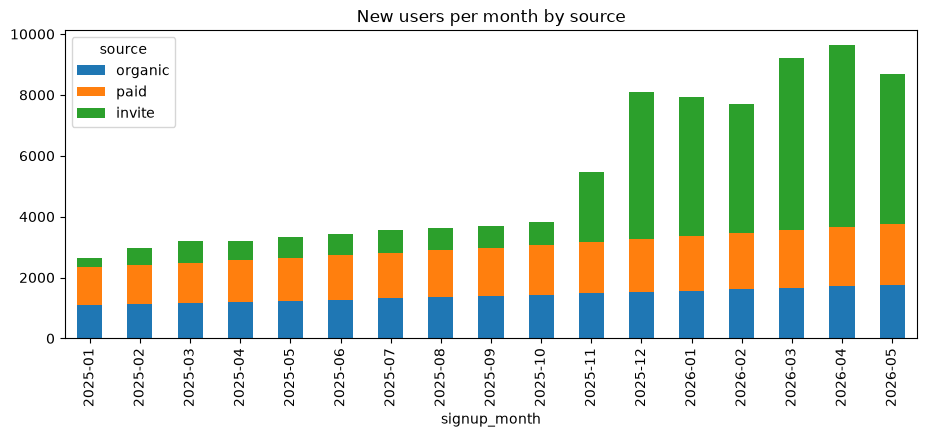

In [20]:
pd.options.display.float_format = "{:,.3f}".format   # show numbers with 3 decimals

monthly_signups = full.pivot_table(index="signup_month", columns="source", values="user_id", aggfunc="count")
monthly_signups["total"] = monthly_signups.sum(axis=1)
monthly_signups["invite_share"] = monthly_signups["invite"] / monthly_signups["total"]
display(monthly_signups)
monthly_signups[["organic", "paid", "invite"]].plot(kind="bar", stacked=True, figsize=(11, 4), title="New users per month by source")
plt.show()

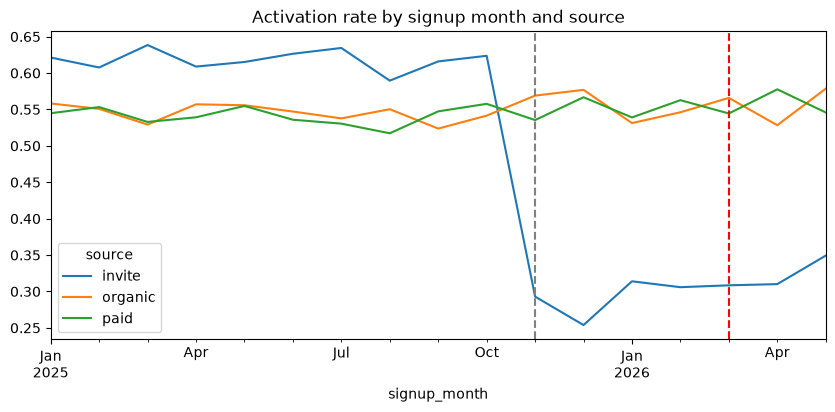

In [21]:
act_month = full.pivot_table(index="signup_month", columns="source", values="activated", aggfunc="mean")
act_month.plot(figsize=(10, 4), title="Activation rate by signup month and source")
plt.axvline(pd.Period("2025-11"), color="gray", ls="--")
plt.axvline(pd.Period("2026-03"), color="red", ls="--")
plt.show()

* Paid and organic grow smoothly (about 3% per month) and did not change when the product changed, so they work as a control group.
* The explosion is the invite channel: about 650 signups per month before the bonus, 4,000 after the bonus, 5,500 after the contact sync. Invites are now 55 to 62% of new users.
* Quality fell: invitee activation dropped from 62% to 29 to 32%, while paid and organic stay near 55%.
### 3.1 Loop funnel: invites, signups, activated, retained

,invites_sent,signups,activated,accept_rate,activation_rate,retained_given_activated,good_per_1000_invites
period,,,,,,,
1_before_referral,26306,6495,4016,0.247,0.618,0.486,74.166
2_referral_bonus,40826,15992,4647,0.392,0.291,0.243,27.605
3_referral_plus_sync,117053,16555,5317,0.141,0.321,0.240,10.893


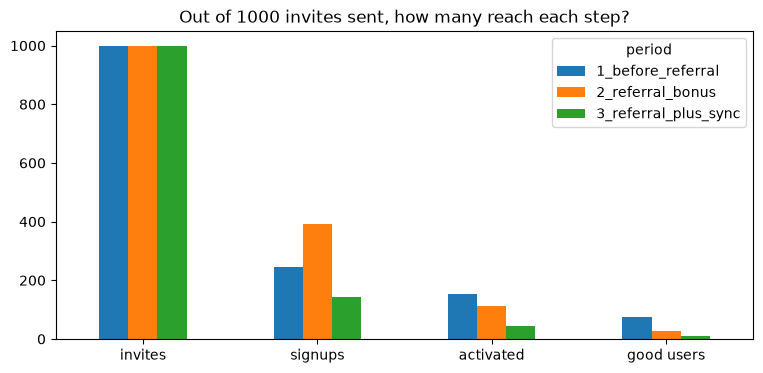

In [22]:
acc = inv_full[inv_full.accepted == 1].merge(
    users[["user_id", "activated", "retained_30", "good_user", "obs_30"]],
    left_on="invitee_user_id", right_on="user_id", how="left")

def funnel(df_inv, df_acc, by):
    out = pd.DataFrame({"invites_sent": df_inv.groupby(by).size()})
    out["signups"] = df_acc.groupby(by).size()
    out["activated"] = df_acc.groupby(by).activated.sum()
    out["accept_rate"] = out.signups / out.invites_sent
    out["activation_rate"] = out.activated / out.signups
    # retention only for invitees with 30 days of history
    a30 = df_acc[(df_acc.obs_30) & (df_acc.activated == 1)]
    out["retained_given_activated"] = a30.groupby(by).retained_30.mean()
    out["good_per_1000_invites"] = 1000 * out.accept_rate * out.activation_rate * out.retained_given_activated
    return out

f_period = funnel(inv_full, acc, "period")
display(f_period)
steps = pd.DataFrame({
    "invites": 1000,
    "signups": 1000 * f_period.accept_rate,
    "activated": 1000 * f_period.accept_rate * f_period.activation_rate,
    "good users": f_period.good_per_1000_invites})
steps.T.plot(kind="bar", figsize=(9, 4), title="Out of 1000 invites sent, how many reach each step?")
plt.xticks(rotation=0)
plt.show()

Out of 1,000 invites: 74 good users before the bonus, 28 with the bonus, 11 with bonus plus sync. An invite became 7 times less efficient. Three leaks:
1. Invite to signup: acceptance went 25% to 39% (bonus) to 14% (sync floods people with automatic SMS).
2. Signup to first split: activation halved (62% to 29 to 32%). Many people sign up for the reward.
3. Activated to active at day 30: also halved (49% to 24%).
### 3.2 Funnel by invite channel (period 3, same period for a fair comparison)

In [23]:
p3_inv = inv_full[inv_full.period == "3_referral_plus_sync"]
p3_acc = acc[acc.invite_id.isin(p3_inv.invite_id)]
f_channel = funnel(p3_inv, p3_acc, "channel")
display(f_channel)

print("share of invites that are auto SMS:", round((p3_inv.channel == "auto_sms_contact_sync").mean(), 3))
print("share of accepted invites from auto SMS:", round((p3_acc.channel == "auto_sms_contact_sync").mean(), 3))

,invites_sent,signups,activated,accept_rate,activation_rate,retained_given_activated,good_per_1000_invites
channel,,,,,,,
auto_sms_contact_sync,78494,1997,726,0.025,0.364,0.212,1.962
link,11762,5058,924,0.430,0.183,0.245,19.214
sms,7202,1616,600,0.224,0.371,0.235,19.578
whatsapp,19595,7884,3067,0.402,0.389,0.246,38.479


share of invites that are auto SMS: 0.671
share of accepted invites from auto SMS: 0.121


* Auto SMS is 67% of invites but only 12% of accepted ones (acceptance 2.5% vs 40% WhatsApp and 43% link).
* Good users per 1,000 invites: WhatsApp 38, SMS 20, link 19, auto SMS 2.
* Link has high acceptance but the lowest activation (18%), a typical sign of reward hunting or links shared in open groups.
### 3.3 Reward leakage

In [24]:
rw = rewards.copy()
rw["month"] = rw.paid_date.dt.to_period("M")
leak = rw.groupby("month").agg(rewards=("reward_id", "count"), cost_eur=("total_cost_eur", "sum"),
                              paid_without_split=("invitee_activated", lambda s: (s == 0).sum()))
leak["leak_eur"] = leak.paid_without_split * 10
leak["leak_share"] = leak.paid_without_split / leak.rewards
display(leak)
print("total reward cost (euros):", rw.total_cost_eur.sum())
print("paid to invitees with 0 splits (euros):", (rw.invitee_activated == 0).sum() * 10,
      "=", round((rw.invitee_activated == 0).mean() * 100, 1), "% of the budget")

,rewards,cost_eur,paid_without_split,leak_eur,leak_share
month,,,,,
2025-11,880,"8,800.000",454,4540,0.516
2025-12,2602,"26,020.000",1390,13900,0.534
2026-01,2295,"22,950.000",860,8600,0.375
2026-02,2089,"20,890.000",811,8110,0.388
2026-03,2620,"26,200.000",908,9080,0.347
2026-04,2879,"28,790.000",1017,10170,0.353
2026-05,2219,"22,190.000",464,4640,0.209
2026-06,949,"9,490.000",230,2300,0.242


total reward cost (euros): 165330.0
paid to invitees with 0 splits (euros): 61340 = 37.1 % of the budget


The bonus cost EUR 165,330 and 37% (EUR 61,340) went to invitees who never made a split, against the rule. The leak was 53% in Dec 2025 and fell to about 21% in May 2026, so something changed in the process. We should ask engineering.

## 4. Is the viral coefficient really close to 1?

K = invites sent per user x conversion of an invite into a new user. Equivalent and easier to audit: K = new users brought by a cohort / size of that cohort.

We do not know the exact formula the team used, so first we reproduce the most common shortcut and then correct it step by step.

In [25]:
# step 1: the shortcut, invites per INVITER x acceptance, on the raw file
inviters_raw = invites_raw.inviter_user_id.nunique()
invites_per_inviter = len(invites_raw) / inviters_raw
accept_raw = invites_raw.accepted.mean()
K_headline = invites_per_inviter * accept_raw
print("invites per inviter:", round(invites_per_inviter, 2), "| acceptance:", round(accept_raw, 3))
print("K headline:", round(K_headline, 2))
# only some users invite anybody
senders = users[users.user_id.isin(invites.inviter_user_id)]
print("share of users who ever sent an invite:", round(len(senders) / len(users), 3))
print("share of inviters that are activated:", round(senders.activated.mean(), 3))

# step 2: divide by all users, clean data
K_per_user = len(invites) / len(users) * invites.accepted.mean()
print("K per user, clean data:", round(K_per_user, 3))

invites per inviter: 5.59 | acceptance: 0.204
K headline: 1.14
share of users who ever sent an invite: 0.376
share of inviters that are activated: 1.0
K per user, clean data: 0.426


The shortcut gives K = 5.6 x 20.4% = 1.14. It is wrong for three reasons: it divides by inviters only (just 37.6% of users invite), it counts duplicated and QA invites, and it counts signups that never use the app. Dividing by all users with clean data gives 0.43.
### 4.1 K by inviter cohort

In [26]:
inviter_info = users[["user_id", "signup_month", "signup_date"]].rename(columns={
    "user_id": "inviter_user_id", "signup_month": "inviter_cohort", "signup_date": "inviter_signup"})
invited = users[(users.source == "invite") & (users.signup_date <= LAST_FULL)].merge(
    inviter_info, on="inviter_user_id", how="inner")
invited["delay_days"] = (invited.signup_date - invited.inviter_signup).dt.days
display(invited.delay_days.describe().to_frame().T)

,count,mean,std,min,25%,50%,75%,max
delay_days,"39,037.000",14.277,8.632,0.000,7.000,14.000,22.000,29.000


Invitees sign up 14 days on average after the inviter (max 29), so cohorts up to April 2026 are complete.

,invitees,activated,good,cohort_size,K_all,K_activated,K_good
inviter_cohort,,,,,,,
2025-01,561,352,181,2651,0.212,0.133,0.068
2025-02,624,374,150,2973,0.210,0.126,0.050
2025-03,686,438,227,3199,0.214,0.137,0.071
2025-04,651,408,197,3200,0.203,0.128,0.062
2025-05,681,407,204,3330,0.205,0.122,0.061
2025-06,730,459,216,3420,0.213,0.134,0.063
2025-07,750,476,228,3550,0.211,0.134,0.064
2025-08,688,396,197,3615,0.190,0.110,0.054
2025-09,732,457,221,3679,0.199,0.124,0.060


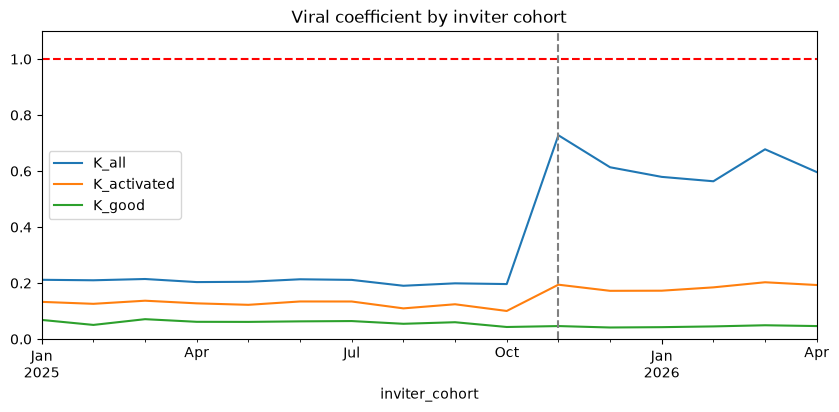

In [27]:
LAST_COHORT = pd.Period("2026-04")
cohort_size = users[users.signup_date <= LAST_FULL].groupby("signup_month").size().rename("cohort_size")

k = invited.groupby("inviter_cohort").agg(invitees=("user_id", "count"), activated=("activated", "sum"))
k["good"] = invited[invited.good_user == 1].groupby("inviter_cohort").size()
k = k.join(cohort_size)
k = k[k.index <= LAST_COHORT]
k["K_all"] = k.invitees / k.cohort_size
k["K_activated"] = k.activated / k.cohort_size
k["K_good"] = k.good / k.cohort_size
display(k)
k[["K_all", "K_activated", "K_good"]].plot(figsize=(10, 4), title="Viral coefficient by inviter cohort")
plt.axhline(1, color="red", ls="--")
plt.axvline(pd.Period("2025-11"), color="gray", ls="--")
plt.ylim(0, 1.1)
plt.show()

,invitees,activated,good,cohort_size,K_invitees,K_activated,K_good
period,,,,,,,
1_before_referral,6851,4149,1985,33426,0.205,0.124,0.059
2_referral_bonus,17882,5248,1272,29202,0.612,0.180,0.044
3_referral_plus_sync,11983,3726,900,18839,0.636,0.198,0.048


,step,K
0,"1 headline (per inviter, raw)",1.144
1,"2 per user, clean",0.426
2,"3 cohort K, all invitees",0.636
3,"4 cohort K, activated invitees",0.198
4,"5 cohort K, good invitees",0.048


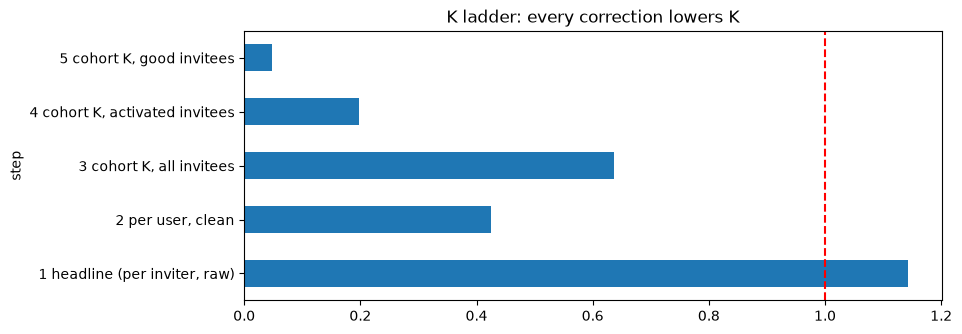

In [28]:
k["period"] = get_period(k.index.to_timestamp())
k_period = k.groupby("period")[["invitees", "activated", "good", "cohort_size"]].sum()
for c in ["invitees", "activated", "good"]:
    k_period["K_" + c] = k_period[c] / k_period.cohort_size
display(k_period)
ladder = pd.DataFrame({
    "step": ["1 headline (per inviter, raw)", "2 per user, clean", "3 cohort K, all invitees",
             "4 cohort K, activated invitees", "5 cohort K, good invitees"],
    "K": [K_headline, K_per_user, k_period.loc["3_referral_plus_sync", "K_invitees"],
          k_period.loc["3_referral_plus_sync", "K_activated"], k_period.loc["3_referral_plus_sync", "K_good"]]})
display(ladder)

ladder.set_index("step").K.plot(kind="barh", figsize=(9, 3.5), title="K ladder: every correction lowers K")
plt.axvline(1, color="red", ls="--")
plt.show()

| Measure | Before bonus | Bonus | Bonus + sync |
|---|---|---|---|
| K, all invitees | 0.21 | 0.61 | 0.64 |
| K, activated invitees | 0.12 | 0.18 | 0.20 |
| K, good invitees | 0.059 | 0.044 | 0.048 |

* The bonus tripled the raw K but K of good users did not improve (0.059 to 0.048). It bought signups, not real users.
* Even the most generous measure (0.64) is below 1. K is not close to 1.
* With K = 0.2 the loop multiplies acquisition by 1/(1-0.2) = 1.25x. With K = 0.05 it is 1.05x. The loop is a booster, not an engine.
### 4.2 K by channel

In [29]:
acc_channel = invites[invites.accepted == 1][["invitee_user_id", "channel"]]
invited_ch = invited.merge(acc_channel, left_on="user_id", right_on="invitee_user_id", how="left")
invited_ch = invited_ch[(invited_ch.inviter_cohort >= pd.Period("2025-11")) & (invited_ch.inviter_cohort <= LAST_COHORT)]
size_ref = cohort_size[(cohort_size.index >= pd.Period("2025-11")) & (cohort_size.index <= LAST_COHORT)].sum()

k_ch = invited_ch.groupby("channel").agg(invitees=("user_id", "count"), activated=("activated", "sum"), good=("good_user", "sum"))
for c in ["invitees", "activated", "good"]:
    k_ch["K_" + c] = k_ch[c] / size_ref
k_ch["good_share_of_signups"] = k_ch.good / k_ch.invitees
display(k_ch)

,invitees,activated,good,K_invitees,K_activated,K_good,good_share_of_signups
channel,,,,,,,
auto_sms_contact_sync,1646,608,128,0.034,0.013,0.003,0.078
link,10857,1695,396,0.226,0.035,0.008,0.036
sms,2891,1115,278,0.060,0.023,0.006,0.096
whatsapp,14471,5556,1370,0.301,0.116,0.029,0.095


WhatsApp produces 63% of the good user K, link 17%, SMS 13% and auto SMS only 7%. Link brings many invitees but only 3.6% are good (9.5% for WhatsApp). Auto SMS only affects the Mar and Apr 2026 cohorts so far, so its weight will grow, but its quality is already visible.

## 5. Channels, segments, countries and periods: does it survive like with like?

In [30]:
def seg_table(df, by):
    out = df.groupby(by).agg(users=("user_id", "count"), activation=("activated", "mean"))
    d30 = df[df.obs_30]
    out["retained_30"] = d30.groupby(by).retained_30.mean()
    out["good_rate"] = d30.groupby(by).good_user.mean()
    out["splits_if_activated"] = df[df.activated == 1].groupby(by).splits_first_30d.mean()
    return out

display(seg_table(full, ["period", "source"]))

users  activation  retained_30  good_rate  \
period               source                                               
1_before_referral    invite    6495       0.618        0.300      0.300   
                     organic  12604       0.545        0.237      0.237   
                     paid     14327       0.541        0.227      0.227   
2_referral_bonus     invite   15992       0.291        0.070      0.070   
                     organic   6183       0.555        0.230      0.230   
                     paid      7027       0.551        0.232      0.232   
3_referral_plus_sync invite   16555       0.321        0.077      0.077   
                     organic   5141       0.558        0.242      0.242   
                     paid      5842       0.556        0.237      0.237   

                              splits_if_activated  
period               source                        
1_before_referral    invite                 3.040  
                     organic                2.817  
                     paid                   2.776  
2_referral_bonus     invite                 2.240  
                     organic                2.843  
                     paid                   2.822  
3_referral_plus_sync invite                 2.299  
                     organic                2.779  
                     paid                   2.854

In [31]:
# does the country explain it? activation by source and country inside each period
display(full.groupby(["period", "source", "country"]).activated.mean().unstack("country"))
display(full[full.source == "invite"].groupby("period").country.value_counts(normalize=True).unstack())

country                         DE    ES    FR    IT  Unknown
period               source                                  
1_before_referral    invite  0.611 0.609 0.621 0.610    0.692
                     organic 0.528 0.541 0.544 0.553    0.592
                     paid    0.548 0.547 0.539 0.539    0.565
2_referral_bonus     invite  0.297 0.294 0.286 0.295    0.263
                     organic 0.568 0.548 0.559 0.554    0.583
                     paid    0.501 0.542 0.563 0.555    0.648
3_referral_plus_sync invite  0.320 0.316 0.324 0.329    0.322
                     organic 0.565 0.559 0.557 0.551    0.573
                     paid    0.582 0.551 0.565 0.528    0.550

country,DE,ES,FR,IT,Unknown
period,,,,,
1_before_referral,0.097,0.093,0.644,0.148,0.018
2_referral_bonus,0.078,0.393,0.395,0.116,0.018
3_referral_plus_sync,0.082,0.390,0.386,0.122,0.020


* Paid and organic are stable and almost identical (activation 54 to 56%, retained at day 30 about 23 to 24%).
* Invitees before the bonus were the best users (activation 62%, 3.0 splits). After the bonus they are the worst (29 to 32%, good rate 7 to 7.7%).
* Countries explain nothing: inside each source and period, FR, ES, IT and DE differ by at most 3 points, even if the country mix of invitees changed a lot.

In [32]:
# like with like: same invite channel before and after the bonus
like = acc.groupby(["channel", "period"]).agg(
    signups=("user_id", "count"), activation=("activated", "mean"))
display(like.unstack("period"))

signups                                        \
period                1_before_referral 2_referral_bonus 3_referral_plus_sync   
channel                                                                         
auto_sms_contact_sync               NaN              NaN            1,997.000   
link                          1,310.000        6,402.000            5,058.000   
sms                             806.000        1,554.000            1,616.000   
whatsapp                      4,379.000        8,036.000            7,884.000   

                             activation                                        
period                1_before_referral 2_referral_bonus 3_referral_plus_sync  
channel                                                                        
auto_sms_contact_sync               NaN              NaN                0.364  
link                              0.627            0.146                0.183  
sms                               0.605            0.405                0.371  
whatsapp                          0.618            0.384                0.389

In [33]:
# reward audit: reward and first split should go together
post = full[(full.source == "invite") & (full.signup_date >= REFERRAL_START)].copy()
post["rewarded"] = post.user_id.isin(rewards.invitee_user_id)
audit = pd.crosstab(post.activated.map({1: "made a split", 0: "no split"}),
                    post.rewarded.map({True: "reward paid", False: "no reward"}))
display(audit)

rewarded,no reward,reward paid
activated,,
made a split,137,9827
no split,16645,5938


It is not a channel mix effect. For the same channel, activation falls after the bonus (WhatsApp 62% to 38%, SMS 61% to 39%, link 63% to 16%). The incentive changed who signs up. The audit shows 5,938 rewards without a split and 137 splits without reward. Hypothesis for the A/B test and the fraud team: some signups come only for the EUR 5.

## 6. Unit economics: CAC, retention, cost per retained user

Splitly does not charge anything yet, so there is no revenue and no real LTV. Our main metric is the **cost per retained user**: how many euros we spend to get one user who made a split and is still active 30 days later. An optional LTV, based on an assumption, is in section 6.4.
### 6.1 Monthly table (also used by the growth model)

,paid_new,paid_act,paid_ret,organic_new,organic_act,organic_ret,invite_new,invite_act,invite_ret,new_total,spend,reward_eur,active,cac_paid,cac_paid_per_activated,referral_cost_per_invitee,blended_cac
2025-01,1250,681,298,1100,614,283,301,187,90,2651,"4,000.000",0.000,1482,3.200,5.874,0.000,1.509
2025-02,1287,712,282,1133,624,261,553,336,156,2973,"4,120.000",0.000,2751,3.201,5.787,0.000,1.386
2025-03,1325,706,298,1166,617,258,708,452,216,3199,"4,240.000",0.000,3661,3.200,6.006,0.000,1.325
2025-04,1365,736,294,1201,669,279,634,386,185,3200,"4,370.000",0.000,4297,3.201,5.938,0.000,1.366
2025-05,1406,780,328,1238,688,309,686,422,217,3330,"4,500.000",0.000,5076,3.201,5.769,0.000,1.351
2025-06,1450,777,343,1274,697,312,696,436,212,3420,"4,640.000",0.000,5721,3.200,5.972,0.000,1.357
2025-07,1493,792,345,1313,706,307,744,472,208,3550,"4,780.000",0.000,6412,3.202,6.035,0.000,1.346
2025-08,1537,795,331,1352,744,331,726,428,219,3615,"4,920.000",0.000,6937,3.201,6.189,0.000,1.361
2025-09,1584,867,346,1392,729,315,703,433,207,3679,"5,070.000",0.000,7386,3.201,5.848,0.000,1.378
2025-10,1630,909,391,1435,777,336,744,464,241,3809,"5,220.000",0.000,7956,3.202,5.743,0.000,1.370


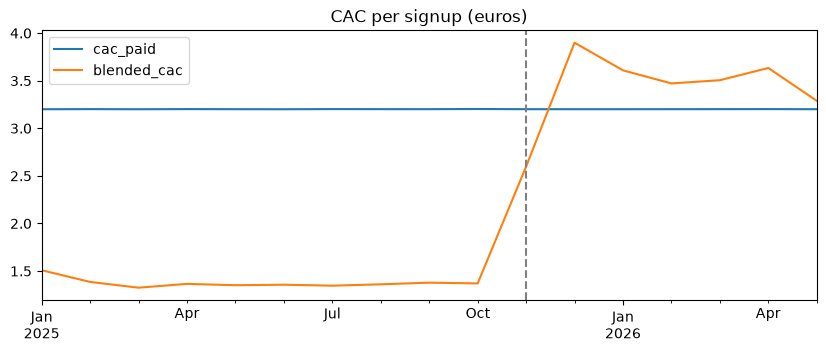

In [34]:
months = pd.period_range("2025-01", "2026-05", freq="M")
monthly = pd.DataFrame(index=months)
for s in ["paid", "organic", "invite"]:
    monthly[s + "_new"] = full[full.source == s].groupby("signup_month").size()
    monthly[s + "_act"] = full[full.source == s].groupby("signup_month").activated.sum()
    monthly[s + "_ret"] = full[full.source == s].groupby("signup_month").good_user.sum()   # retained = activated and active 30+ days
monthly["new_total"] = monthly[["paid_new", "organic_new", "invite_new"]].sum(axis=1)

spend["pm"] = spend.month.dt.to_period("M")
rewards["pm"] = rewards.paid_date.dt.to_period("M")
monthly["spend"] = spend.set_index("pm").spend_eur
monthly["reward_eur"] = rewards.groupby("pm").total_cost_eur.sum()
monthly["reward_eur"] = monthly["reward_eur"].fillna(0)
# active base: activated users already signed up and with activity on or after the 1st of the month
active = []
for m in months:
    first_day, last_day = m.start_time, m.end_time.normalize()
    active.append(((users.activated == 1) & (users.signup_date <= last_day) & (users.last_active_date >= first_day)).sum())
monthly["active"] = active
monthly["cac_paid"] = monthly.spend / monthly.paid_new
monthly["cac_paid_per_activated"] = monthly.spend / monthly.paid_act
monthly["referral_cost_per_invitee"] = monthly.reward_eur / monthly.invite_new
monthly["blended_cac"] = (monthly.spend + monthly.reward_eur) / monthly.new_total
display(monthly)

monthly[["cac_paid", "blended_cac"]].plot(figsize=(10, 3.5), title="CAC per signup (euros)")
plt.axvline(pd.Period("2025-11"), color="gray", ls="--")
plt.show()

* Paid CAC is flat: EUR 3.20 per signup (EUR 5.9 per activated user) in all 18 months, no sign of saturation.
* Blended CAC jumped from EUR 1.35 to EUR 3.3 to 3.9 after the bonus. Each invitee costs about EUR 4.5 to 5.4 in rewards, more than a paid signup.
* Per retained user: paid about EUR 14, referral about EUR 60 to 70 (see 6.3). The "free" viral growth is 4 to 5 times more expensive than ads per retained user.
### 6.2 Retention curves

S(k) is the share of activated users still active k x 30 days after signup. To be fair we only use users who signed up by 2025-12-31 (all have 180 days of history).

,S(0),S(1),S(2),S(3),S(4),S(5),S(6)
paid,1.000,0.419,0.388,0.353,0.318,0.283,0.250
organic,1.000,0.431,0.400,0.365,0.332,0.297,0.261
invite_before_bonus,1.000,0.486,0.451,0.409,0.365,0.327,0.287
invite_after_bonus,1.000,0.245,0.230,0.210,0.192,0.173,0.152


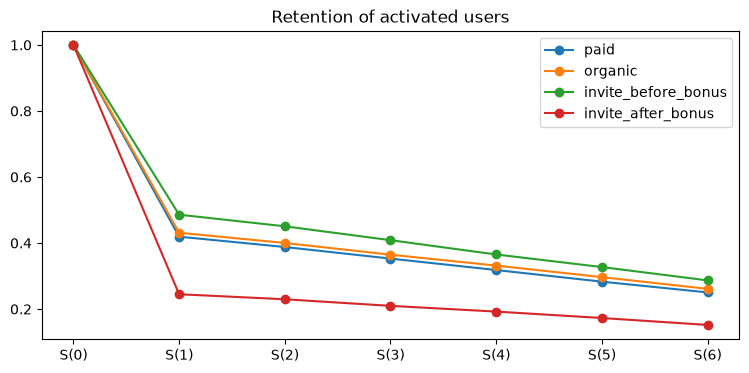

In [35]:
SEG_END = pd.Timestamp("2025-12-31")

def make_segment(df):
    return np.select([df.source == "paid", df.source == "organic",
                      (df.source == "invite") & (df.signup_date < REFERRAL_START)],
                     ["paid", "organic", "invite_before_bonus"], default="invite_after_bonus")

all_seg_users = users[users.signup_date <= SEG_END].copy()
all_seg_users["segment"] = make_segment(all_seg_users)
act_users = all_seg_users[all_seg_users.activated == 1]
curve = pd.DataFrame({"S(0)": 1.0}, index=act_users.segment.unique())
for kk in range(1, 7):
    curve[f"S({kk})"] = act_users.groupby("segment").life_days.apply(lambda s: (s >= 30 * kk).mean())
display(curve)

curve.T.plot(figsize=(9, 4), marker="o", title="Retention of activated users")
plt.show()

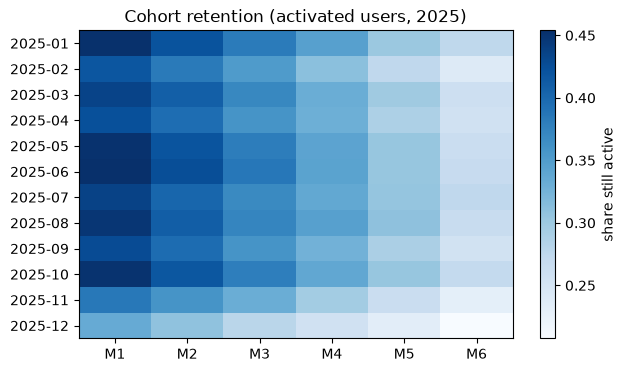

In [36]:
# cohort heatmap for 2025 cohorts
cohort = pd.DataFrame(index=pd.period_range("2025-01", "2025-12", freq="M"), columns=range(1, 7), dtype=float)
a_users = users[users.activated == 1]
for m in cohort.index:
    d = a_users[a_users.signup_month == m]
    for kk in cohort.columns:
        cohort.loc[m, kk] = (d.life_days >= 30 * kk).mean()

plt.figure(figsize=(7, 4))
plt.imshow(cohort.values.astype(float), aspect="auto", cmap="Blues")
plt.yticks(range(len(cohort)), cohort.index.astype(str))
plt.xticks(range(6), [f"M{c}" for c in cohort.columns])
plt.colorbar(label="share still active")
plt.title("Cohort retention (activated users, 2025)")
plt.show()

* Still active after 1 and 6 months: paid 42% and 25%, organic 43% and 26%, invite before bonus 49% and 29%, invite after bonus 25% and 15%.
* Bonus invitees lose three quarters of the users in the first 30 days. After that the decay is similar for everybody (8 to 10% per month), so the damage is at the start: onboarding and incentive quality.
* Jan to Oct 2025 cohorts are very stable, so no strong seasonality. The drop starts with the Nov to Dec 2025 cohorts.
### 6.3 CAC and cost per retained user (main metric)

Retained user = made at least one split and still active 30 days after signup (our "good user"). Cost per retained user = euros spent / retained users.
* Paid: ad spend / paid retained users.
* Referral: reward euros / invited retained users.
* Blended: (ad spend + rewards) / all retained users. Organic users cost nothing.

,paid_cac_per_signup,paid_cac_per_activated,paid_cost_per_retained,referral_cost_per_signup,referral_cost_per_retained,blended_cost_per_retained,referral_vs_paid_x
period,,,,,,,
1_before_referral,3.201,5.914,14.085,NaN,NaN,5.594,NaN
2_referral_bonus,3.201,5.807,13.806,4.919,69.796,24.193,5.055
3_referral_plus_sync,3.201,5.757,13.512,4.662,60.533,24.566,4.480


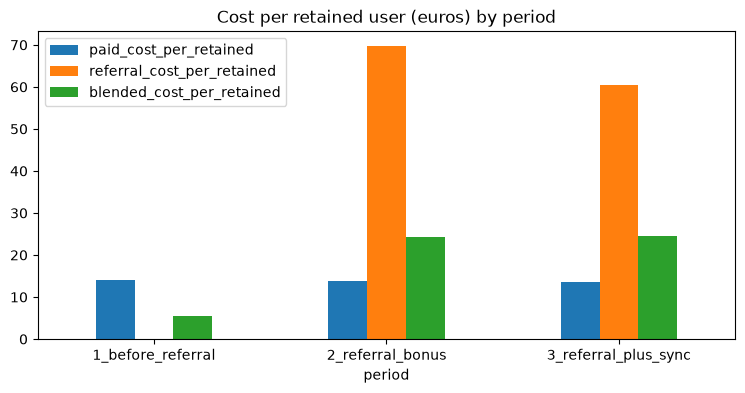

In [37]:
monthly["period"] = get_period(monthly.index.to_timestamp())
monthly["new_ret"] = monthly.paid_ret + monthly.organic_ret + monthly.invite_ret   # all retained users of the month

# add the months of each period
cols = ["spend", "reward_eur", "paid_new", "paid_act", "paid_ret",
        "organic_ret", "invite_new", "invite_act", "invite_ret", "new_ret"]
tot = monthly.groupby("period")[cols].sum()

cost = pd.DataFrame(index=tot.index)
cost["paid_cac_per_signup"] = tot.spend / tot.paid_new
cost["paid_cac_per_activated"] = tot.spend / tot.paid_act
cost["paid_cost_per_retained"] = tot.spend / tot.paid_ret
cost["referral_cost_per_signup"] = tot.reward_eur / tot.invite_new
cost["referral_cost_per_retained"] = tot.reward_eur / tot.invite_ret
cost["blended_cost_per_retained"] = (tot.spend + tot.reward_eur) / tot.new_ret
cost["referral_vs_paid_x"] = cost.referral_cost_per_retained / cost.paid_cost_per_retained
# period 1 has no referral reward, so the referral columns are not defined
no_bonus = tot.reward_eur == 0
cost.loc[no_bonus, ["referral_cost_per_signup", "referral_cost_per_retained", "referral_vs_paid_x"]] = np.nan
display(cost)

cost[["paid_cost_per_retained", "referral_cost_per_retained", "blended_cost_per_retained"]].plot(
    kind="bar", figsize=(9, 4), title="Cost per retained user (euros) by period")
plt.xticks(rotation=0)
plt.show()

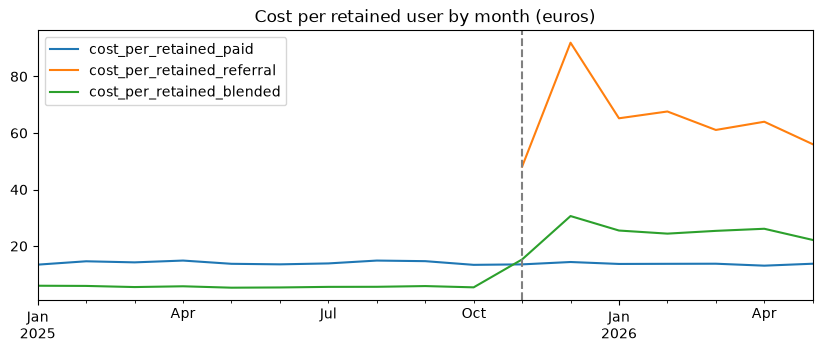

In [38]:
# same metric month by month
monthly["cost_per_retained_paid"] = monthly.spend / monthly.paid_ret
monthly["cost_per_retained_referral"] = (monthly.reward_eur / monthly.invite_ret).replace(0, np.nan)
monthly["cost_per_retained_blended"] = (monthly.spend + monthly.reward_eur) / monthly.new_ret
monthly[["cost_per_retained_paid", "cost_per_retained_referral", "cost_per_retained_blended"]].plot(
    figsize=(10, 3.5), title="Cost per retained user by month (euros)")
plt.axvline(pd.Period("2025-11"), color="gray", ls="--")
plt.show()

* Paid is stable at about EUR 14 per retained user (EUR 14.1, 13.8, 13.5 in the three periods).
* Referral costs EUR 69.8 with the bonus and EUR 60.5 with bonus plus sync: 4.5 to 5 times more than paid.
* Blended cost went from EUR 5.6 (before the bonus, only ads) to about EUR 24 after it, because most rewards go to invitees who do not stay.


### 6.4 Optional: LTV with a monetisation assumption

There is no revenue in the data, so this part is an **assumption**, not a result. 

Comparable apps charge a similar price: Splitwise Pro USD 2.99 to 4.99 per month and Settle Up Premium about USD 3.49 per month (annual plans are cheaper per month). Other apps, like Tricount, are free with ads and an optional subscription.

 We test other values in the scenarios of section 9.3.

* ARPU = share of active users who pay x price per month.
* LTV per active user = ARPU x gross margin / monthly churn.
* CAC per activated paid user = ad spend / paid activated users.
* Payback (months) = CAC / (ARPU x gross margin).

In [39]:
GROSS_MARGIN = 0.80    # assumption: app stores keep 15 to 30% of the revenue
PAYING_SHARE = 0.025   # assumption: share of ACTIVE users who pay
PRICE = 3.00           # assumption: euros per month

last3 = monthly.iloc[-3:]                                    # Mar to May 2026, same as the growth model
new_activated = monthly.paid_act + monthly.organic_act + monthly.invite_act
churn_by_month = (monthly.active.shift(1) + new_activated - monthly.active) / monthly.active.shift(1)
churn_now = churn_by_month.iloc[-3:].mean()                  # monthly churn of the active base
cac_activated = last3.spend.sum() / last3.paid_act.sum()     # CAC per activated paid user

arpu = PAYING_SHARE * PRICE
ltv = arpu * GROSS_MARGIN / churn_now
print(f"ARPU: {arpu:.3f} euros per active user per month")
print(f"LTV per active user: {ltv:.2f} euros | CAC per activated paid user: {cac_activated:.2f} euros")
print(f"LTV:CAC = {ltv / cac_activated:.3f}")
print(f"CAC payback = {cac_activated / (arpu * GROSS_MARGIN):.0f} months")
print(f"ARPU needed for LTV:CAC = 3: {3 * cac_activated * churn_now / GROSS_MARGIN:.2f} euros per active user per month")
print(f"ARPU needed for a 12 month payback: {cac_activated / (12 * GROSS_MARGIN):.2f} euros per active user per month")

ARPU: 0.075 euros per active user per month
LTV per active user: 0.22 euros | CAC per activated paid user: 5.76 euros
LTV:CAC = 0.038
CAC payback = 96 months
ARPU needed for LTV:CAC = 3: 5.90 euros per active user per month
ARPU needed for a 12 month payback: 0.60 euros per active user per month


In [40]:
# LTV:CAC for different paying shares and prices
grid = pd.DataFrame(index=[0.01, 0.02, 0.03, 0.05, 0.10, 0.20], columns=[2.5, 3, 4, 5, 6], dtype=float)
for share in grid.index:
    for price in grid.columns:
        grid.loc[share, price] = share * price * GROSS_MARGIN / churn_now / cac_activated
grid.index.name, grid.columns.name = "paying share", "price EUR/month"
display(grid.round(2))

price EUR/month,2.500,3.000,4.000,5.000,6.000
paying share,,,,,
0.010,0.010,0.020,0.020,0.030,0.030
0.020,0.030,0.030,0.040,0.050,0.060
0.030,0.040,0.050,0.060,0.080,0.090
0.050,0.060,0.080,0.100,0.130,0.150
0.100,0.130,0.150,0.200,0.250,0.310
0.200,0.250,0.310,0.410,0.510,0.610


* With 2.5% of active users paying EUR 3 per month, LTV is about EUR 0.22 per active user against a CAC of EUR 5.8: LTV:CAC is 0.04 and the payback is about 8 years.
* Even if 20% of the users paid EUR 6, LTV:CAC would be 0.6. To reach 3 we would need about EUR 5.9 per active user per month, which is more than the price of Splitwise Pro even if every active user paid.
* Conclusion: with a subscription of this size the paid channel cannot be justified by LTV. This is why the cost per retained user is our main metric.
* Caveat: every number here depends on the assumptions above, not on Splitly data.

## 7. What changed and what did it cause?

Two changes: the Nov 2025 referral bonus and the Mar 2026 contact sync. A before and after comparison does not prove causality, but paid and organic did not change, so they act as a control.

In [41]:
ev = pd.DataFrame(index=monthly.index)
ev["invites_sent"] = inv_full.groupby("sent_month").size()
ev["auto_sms_invites"] = inv_full[inv_full.channel == "auto_sms_contact_sync"].groupby("sent_month").size()
ev["auto_sms_invites"] = ev.auto_sms_invites.fillna(0)
ev["invited_signups"] = monthly.invite_new
ev["accept_rate"] = ev.invited_signups / ev.invites_sent
ev["invitee_activation"] = monthly.invite_act / monthly.invite_new
ev["paid_signups"] = monthly.paid_new
ev["organic_signups"] = monthly.organic_new
ev["reward_eur"] = monthly.reward_eur
r = ratings.copy()
r["m"] = r.month.dt.to_period("M")
r = r.set_index("m")
ev["store_rating"] = r.avg_store_rating
ev["n_reviews"] = r.n_reviews
ev["share_1_star"] = r.share_1_star
ev["period"] = get_period(ev.index.to_timestamp())
display(ev)
display(ev.groupby("period").mean(numeric_only=True).T)

,invites_sent,auto_sms_invites,invited_signups,accept_rate,invitee_activation,paid_signups,organic_signups,reward_eur,store_rating,n_reviews,share_1_star,period
2025-01,1151,0.000,301,0.262,0.621,1250,1100,0.000,4.590,300.000,0.071,1_before_referral
2025-02,2200,0.000,553,0.251,0.608,1287,1133,0.000,4.590,309.000,0.071,1_before_referral
2025-03,2798,0.000,708,0.253,0.638,1325,1166,0.000,4.500,318.000,0.099,1_before_referral
2025-04,2594,0.000,634,0.244,0.609,1365,1201,0.000,4.590,327.000,0.069,1_before_referral
2025-05,2816,0.000,686,0.244,0.615,1406,1238,0.000,4.600,337.000,0.065,1_before_referral
2025-06,2807,0.000,696,0.248,0.626,1450,1274,0.000,4.650,347.000,0.049,1_before_referral
2025-07,2989,0.000,744,0.249,0.634,1493,1313,0.000,NaN,NaN,NaN,1_before_referral
2025-08,2956,0.000,726,0.246,0.590,1537,1352,0.000,4.610,368.000,0.062,1_before_referral
2025-09,2876,0.000,703,0.244,0.616,1584,1392,0.000,4.600,380.000,0.065,1_before_referral
2025-10,3119,0.000,744,0.239,0.624,1630,1435,0.000,4.570,391.000,0.076,1_before_referral


period,1_before_referral,2_referral_bonus,3_referral_plus_sync
invites_sent,"2,630.600","10,206.500","39,017.667"
auto_sms_invites,0.000,0.000,"26,164.667"
invited_signups,649.500,"3,998.000","5,518.333"
accept_rate,0.248,0.390,0.145
invitee_activation,0.618,0.292,0.323
paid_signups,"1,432.700","1,756.750","1,947.333"
organic_signups,"1,260.400","1,545.750","1,713.667"
reward_eur,0.000,"19,665.000","25,726.667"
store_rating,4.589,4.433,3.537
n_reviews,341.889,421.250,841.000


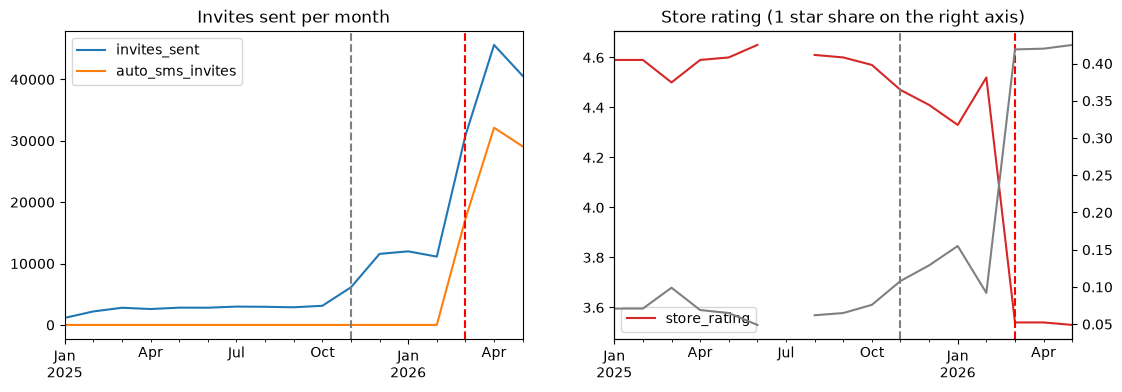

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ev[["invites_sent", "auto_sms_invites"]].plot(ax=ax[0], title="Invites sent per month")
ev[["store_rating"]].plot(ax=ax[1], color="tab:red", title="Store rating (1 star share on the right axis)")
ev.share_1_star.plot(ax=ax[1], secondary_y=True, color="gray")
for a in ax:
    a.axvline(pd.Period("2025-11"), color="gray", ls="--")
    a.axvline(pd.Period("2026-03"), color="red", ls="--")
plt.show()

In [43]:
# good users from invites and the cost of the bonus
obs = full[full.obs_30]
imp = pd.DataFrame({
    "good_users_invite": obs[obs.source == "invite"].groupby("signup_month").good_user.sum(),
    "good_users_paid": obs[obs.source == "paid"].groupby("signup_month").good_user.sum()})
imp["reward_eur"] = monthly.reward_eur
imp["reward_eur_per_good_invitee"] = imp.reward_eur / imp.good_users_invite
imp["paid_eur_per_good_paid_user"] = monthly.spend / imp.good_users_paid
imp["period"] = ev.period
display(imp.dropna(subset=["good_users_invite"]))
display(imp.groupby("period").mean(numeric_only=True))

,good_users_invite,good_users_paid,reward_eur,reward_eur_per_good_invitee,paid_eur_per_good_paid_user,period
signup_month,,,,,,
2025-01,90,298,0.000,0.000,13.423,1_before_referral
2025-02,156,282,0.000,0.000,14.610,1_before_referral
2025-03,216,298,0.000,0.000,14.228,1_before_referral
2025-04,185,294,0.000,0.000,14.864,1_before_referral
2025-05,217,328,0.000,0.000,13.720,1_before_referral
2025-06,212,343,0.000,0.000,13.528,1_before_referral
2025-07,208,345,0.000,0.000,13.855,1_before_referral
2025-08,219,331,0.000,0.000,14.864,1_before_referral
2025-09,207,346,0.000,0.000,14.653,1_before_referral


,good_users_invite,good_users_paid,reward_eur,reward_eur_per_good_invitee,paid_eur_per_good_paid_user
period,,,,,
1_before_referral,195.100,325.600,0.000,0.000,14.109
2_referral_bonus,281.750,407.250,"19,665.000",68.209,13.813
3_referral_plus_sync,425.000,461.333,"25,726.667",60.362,13.519


| | Nov 2025 bonus | Mar 2026 contact sync |
|---|---|---|
| Invites per month | 2.6k to 10.2k | 10.2k to 39.0k (67% auto SMS) |
| Acceptance | 25% to 39% | 39% to 14.5% |
| Invited signups per month | 650 to 4,000 | 4,000 to 5,500 |
| Invitee activation | 62% to 29% | 29% to 32% |
| Good invitees per month | 195 to 282 | 282 to 425 |
| Reward cost per month | 0 to EUR 19.7k | EUR 25.7k |
| Store rating | 4.59 to 4.43 | 4.43 to 3.54 |
| 1 star share | 7% to 12% | 12% to 42% |

* Bonus: x6 invited signups, but activation halved and about EUR 68 per good invitee.
* Contact sync: about +1,500 invited signups and +140 good users per month, but 26k automatic SMS per month at 2.5% acceptance, and the rating fell 0.9 stars in one month (Feb 4.52 to Mar 3.54).
* Paid and organic signups have not suffered yet, but a 3.5 star rating is a risk for store conversion.
## 8. North Star Metric

Candidates: signups (vanity), invites sent (inflated by auto SMS), K, active users, or a quality measure. Our proposal: good users per month, meaning new users who made a first split and are still active 30 days later. If the metric is good it should not double just because we send more SMS.

,signups,invites_sent,good_users,good_per_100_signups
2025-01,2651,1151,671,25.311
2025-02,2973,2200,699,23.512
2025-03,3199,2798,772,24.133
2025-04,3200,2594,758,23.688
2025-05,3330,2816,854,25.646
2025-06,3420,2807,867,25.351
2025-07,3550,2989,860,24.225
2025-08,3615,2956,881,24.371
2025-09,3679,2876,868,23.593
2025-10,3809,3119,968,25.413


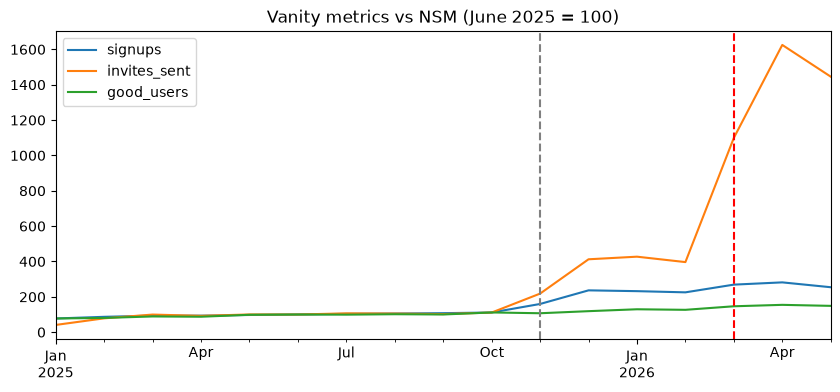

In [44]:
nsm = pd.DataFrame(index=months)
nsm["signups"] = monthly.new_total
nsm["invites_sent"] = ev.invites_sent
nsm["good_users"] = full[full.obs_30].groupby("signup_month").good_user.sum()
nsm["good_per_100_signups"] = 100 * nsm.good_users / nsm.signups
display(nsm)
idx = nsm[["signups", "invites_sent", "good_users"]] / nsm.loc[pd.Period("2025-06"), ["signups", "invites_sent", "good_users"]] * 100
idx.plot(figsize=(10, 4), title="Vanity metrics vs NSM (June 2025 = 100)")
plt.axvline(pd.Period("2025-11"), color="gray", ls="--")
plt.axvline(pd.Period("2026-03"), color="red", ls="--")
plt.show()

From June 2025 to May 2026 signups grew 154% and invites sent x14.5, but good users only 49% (868 to 1,291). Good users per 100 signups fell from 25 to about 14.

Why it is the right metric: it measures value delivered, combines activation and retention (where the funnel leaks), is not inflated by the bonus or auto SMS, feeds the loop (only activated users invite), and the whole team can move it. Companion metrics: K of good users, reward euros per good invitee, and store rating as a guardrail. Counter metric against tunnel vision: paid cost per retained user.
## 9. Growth model, backtest and 3 scenarios

### 9.1 Model design

Each month: paid users = spend / CAC, organic users grow at a fixed rate, invited users = v x active base (v is invited signups per active user), new activated users = each source x its activation rate, and active base = last active x (1 - churn) + new activated. Parameters are averages of the last 3 training months.

K of the model = v x act_inv / churn: activated users that one active user brings during its life. If K is 1 or more the loop sustains itself without ads.

The model also counts **new retained users** each month (activated users x the share still active at day 30), so we can compute the cost per retained user in every scenario.

In [45]:
monthly["new_activated"] = monthly.paid_act + monthly.organic_act + monthly.invite_act
monthly["churn"] = (monthly.active.shift(1) + monthly.new_activated - monthly.active) / monthly.active.shift(1)
monthly["v"] = monthly.invite_new / monthly.active.shift(1)
monthly["org_growth"] = monthly.organic_new.pct_change()
display(monthly[["active", "new_activated", "churn", "v", "org_growth"]])

,active,new_activated,churn,v,org_growth
2025-01,1482,1482,NaN,NaN,NaN
2025-02,2751,1672,0.272,0.373,0.030
2025-03,3661,1775,0.314,0.257,0.029
2025-04,4297,1791,0.315,0.173,0.030
2025-05,5076,1890,0.259,0.160,0.031
2025-06,5721,1910,0.249,0.137,0.029
2025-07,6412,1970,0.224,0.130,0.031
2025-08,6937,1967,0.225,0.113,0.030
2025-09,7386,2029,0.228,0.101,0.030
2025-10,7956,2150,0.214,0.101,0.031


In [46]:
def get_params(train_months):
    t = monthly.loc[train_months]
    return {
        "cac_paid": t.spend.sum() / t.paid_new.sum(),
        "act_paid": t.paid_act.sum() / t.paid_new.sum(),
        "act_org": t.organic_act.sum() / t.organic_new.sum(),
        "act_inv": t.invite_act.sum() / t.invite_new.sum(),
        "v": t.v.mean(),
        "churn": t.churn.mean(),
        "org_growth": t.org_growth.mean(),
        "reward_per_invitee": t.reward_eur.sum() / t.invite_new.sum(),
        # share of activated users still active at day 30 (to count retained users)
        "ret_paid": t.paid_ret.sum() / t.paid_act.sum(),
        "ret_org": t.organic_ret.sum() / t.organic_act.sum(),
        "ret_inv": t.invite_ret.sum() / t.invite_act.sum()}

In [47]:
def simulate(p, start_active, start_organic, spend_list):
    rows = []
    A, org = start_active, start_organic
    for s in spend_list:
        paid = s / p["cac_paid"]
        org = org * (1 + p["org_growth"])
        inv = p["v"] * A
        new_act = paid * p["act_paid"] + org * p["act_org"] + inv * p["act_inv"]
        # new retained users = activated users x retention at day 30
        new_ret = (paid * p["act_paid"] * p["ret_paid"] + org * p["act_org"] * p["ret_org"]
                   + inv * p["act_inv"] * p["ret_inv"])
        A = A * (1 - p["churn"]) + new_act
        rows.append({"spend": s, "paid_new": paid, "organic_new": org, "invite_new": inv,
                     "new_total": paid + org + inv, "new_activated": new_act, "new_retained": new_ret,
                     "active": A, "reward_eur": inv * p["reward_per_invitee"]})
    return pd.DataFrame(rows)

In [48]:
p_now = get_params(list(pd.period_range("2026-03", "2026-05", freq="M")))
display(pd.Series(p_now).to_frame("value"))
print("K of the model:", round(p_now["v"] * p_now["act_inv"] / p_now["churn"], 3))
print("loop needs v x act_inv >= churn. Today:", round(p_now["v"] * p_now["act_inv"], 3), "vs churn", round(p_now["churn"], 3))

,value
cac_paid,3.201
act_paid,0.556
act_org,0.558
act_inv,0.321
v,0.476
churn,0.273
org_growth,0.030
reward_per_invitee,4.662
ret_paid,0.426
ret_org,0.434


K of the model: 0.56
loop needs v x act_inv >= churn. Today: 0.153 vs churn 0.273


Parameters (Mar to May 2026): paid CAC EUR 3.20, activation 56% (paid and organic) and 32% (invited), v = 0.48, monthly churn 27%, organic growth 3%. K of the model is 0.56 per active user. The loop is 1.8 times too weak (0.153 vs 0.273).

Warning: v was 0.52 in March, 0.51 in April and 0.40 in May, so invitation intensity is already fading and the base case may be a bit optimistic.
### 9.2 Backtest

We pretend to be at an earlier date, estimate parameters with the 3 previous months, and forecast the next months using the real marketing spend. We compare with a naive forecast that repeats the last training month.

* A: train Dec 2025 to Feb 2026, test Mar to May 2026 (includes the contact sync shock).
* B: train Jan to Mar 2026, test Apr to May 2026.

In [49]:
def backtest(train_last, test_months):
    p = get_params([train_last - 2, train_last - 1, train_last])
    sim = simulate(p, monthly.active[train_last], monthly.organic_new[train_last], monthly.spend[test_months].tolist())
    sim.index = test_months
    real = monthly.loc[test_months]
    return pd.DataFrame({
        "new_total_real": real.new_total, "new_total_model": sim.new_total,
        "invite_new_real": real.invite_new, "invite_new_model": sim.invite_new,
        "active_real": real.active, "active_model": sim.active,
        "active_naive": monthly.active[train_last]})

def mape(real, pred):
    return float(np.mean(np.abs(real - pred) / real) * 100)

In [50]:
tests = {"A": (pd.Period("2026-02"), list(pd.period_range("2026-03", "2026-05", freq="M"))),
         "B": (pd.Period("2026-03"), list(pd.period_range("2026-04", "2026-05", freq="M")))}
bt_rows = []
for name, (train_last, test_m) in tests.items():
    res = backtest(train_last, test_m)
    display(res.round(0))
    bt_rows.append({"backtest": name,
                    "MAPE new users": mape(res.new_total_real, res.new_total_model),
                    "MAPE invited users": mape(res.invite_new_real, res.invite_new_model),
                    "MAPE active (model)": mape(res.active_real, res.active_model),
                    "MAPE active (naive)": mape(res.active_real, res.active_naive)})
    res_B = res
display(pd.DataFrame(bt_rows).set_index("backtest"))

,new_total_real,new_total_model,invite_new_real,invite_new_model,active_real,active_model,active_naive
2026-03,9201,"8,736.000",5648,"5,182.000",11751,"11,620.000",10856
2026-04,9638,"9,206.000",5979,"5,547.000",12330,"12,357.000",10856
2026-05,8699,"9,669.000",4928,"5,899.000",12724,"13,074.000",10856


,new_total_real,new_total_model,invite_new_real,invite_new_model,active_real,active_model,active_naive
2026-04,9638,"9,105.000",5979,"5,446.000",12330,"12,327.000",11751
2026-05,8699,"9,483.000",4928,"5,713.000",12724,"12,894.000",11751


,MAPE new users,MAPE invited users,MAPE active (model),MAPE active (naive)
backtest,,,,
A,6.896,11.726,1.364,11.417
B,7.270,12.423,0.680,6.171


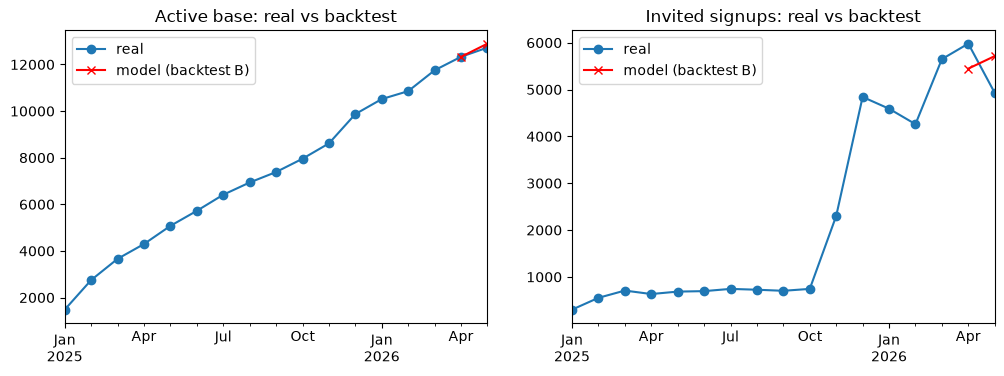

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
monthly.active.plot(ax=ax[0], label="real", marker="o")
res_B.active_model.plot(ax=ax[0], label="model (backtest B)", marker="x", color="red")
ax[0].set_title("Active base: real vs backtest")
ax[0].legend()
monthly.invite_new.plot(ax=ax[1], label="real", marker="o")
res_B.invite_new_model.plot(ax=ax[1], label="model (backtest B)", marker="x", color="red")
ax[1].set_title("Invited signups: real vs backtest")
ax[1].legend()
plt.show()

The model predicts the active base very well (error 1.4% and 0.7%, vs 11.4% and 6.2% for the naive forecast). New users have 7% error. Invited signups have 12% error because the model overshoots May (5,713 vs 4,928): invitation intensity started to decline and constant parameters cannot see that. So the model is reliable for the active base and less for the invite flow, which is why the pessimistic scenario matters.
### 9.3 Three scenarios (Jun 2026 to May 2027)

All start from the real state of May 2026. Spend: real June 2026 value, then the historical monthly growth.

The changes versus Base are **general assumptions** (they do not come directly from the data), anchored on ranges we saw in the data. They are the same values used in the Excel simulator (Inputs sheet). Each scenario also has its own monetisation assumption for the optional LTV.

| Scenario | What changes versus base (Mar to May 2026 parameters) | Paying share, price |
|---|---|---|
| Base | Nothing changes | 2.5%, EUR 3.00 |
| Optimistic | Opt-in sync and reward after real use: CAC -7%, v +15%, invitee activation x1.30, churn -10%, reward cost -15% | 4%, EUR 3.50 |
| Pessimistic | Rating damage and ad fatigue: CAC +22%, v -28%, invitee activation -8%, churn +12% | 1.5%, EUR 2.50 |

In [52]:
spend_growth = spend.spend_eur.pct_change().tail(6).mean()
print("monthly spend growth used:", round(spend_growth, 4))

fut_months = pd.period_range("2026-06", "2027-05", freq="M")
june_spend = spend[spend.pm == pd.Period("2026-06")].spend_eur.iloc[0]
spend_future = [june_spend * (1 + spend_growth) ** i for i in range(12)]

# multipliers on the Base parameters (assumptions)
scenarios = {
    "Base": {},
    "Optimistic": {"cac_paid": 0.93, "v": 1.15, "act_inv": 1.30, "churn": 0.90, "reward_per_invitee": 0.85},
    "Pessimistic": {"cac_paid": 1.22, "v": 0.72, "act_inv": 0.92, "churn": 1.12}}

# monetisation assumption of each scenario: (share of active users who pay, price in euros per month)
monet = {"Base": (0.025, 3.00), "Optimistic": (0.04, 3.50), "Pessimistic": (0.015, 2.50)}
GROSS_MARGIN = 0.80   # same as section 6.4

monthly spend growth used: 0.0299


In [53]:
results, sc_rows = {}, []
for name, mult in scenarios.items():
    p = dict(p_now)
    for key, factor in mult.items():
        p[key] = p[key] * factor
    sim = simulate(p, monthly.active[pd.Period("2026-05")], monthly.organic_new[pd.Period("2026-05")], spend_future)
    sim.index = fut_months
    results[name] = sim

    total_cost = sim.spend.sum() + sim.reward_eur.sum()
    cac_activated = p["cac_paid"] / p["act_paid"]              # CAC per activated paid user
    share, price = monet[name]
    ltv = share * price * GROSS_MARGIN / p["churn"]            # optional LTV per active user

    sc_rows.append({"scenario": name,
                    "K per active user": p["v"] * p["act_inv"] / p["churn"],
                    "v x act_inv": p["v"] * p["act_inv"],
                    "churn": p["churn"],
                    "active base May-27": sim.active.iloc[-1],
                    "new users per month May-27": sim.new_total.iloc[-1],
                    "share of new users from invites": sim.invite_new.iloc[-1] / sim.new_total.iloc[-1],
                    "12m cost EUR": total_cost,
                    "cost per new activated EUR": total_cost / sim.new_activated.sum(),
                    # main metric
                    "cost per retained user EUR (all channels)": total_cost / sim.new_retained.sum(),
                    "cost per retained PAID user EUR": cac_activated / p["ret_paid"],
                    "cost per retained REFERRED user EUR": p["reward_per_invitee"] / p["act_inv"] / p["ret_inv"],
                    # optional, depends on the monetisation assumption
                    "paying share": share, "price EUR/month": price,
                    "LTV:CAC (optional)": ltv / cac_activated})
sc = pd.DataFrame(sc_rows).set_index("scenario")
display(sc.T.round(2))

scenario,Base,Optimistic,Pessimistic
K per active user,0.560,0.930,0.330
v x act_inv,0.150,0.230,0.100
churn,0.270,0.250,0.310
active base May-27,"20,141.750","39,531.950","12,149.880"
new users per month May-27,"14,657.690","25,885.760","8,930.220"
share of new users from invites,0.630,0.780,0.460
12m cost EUR,"522,829.340","732,694.510","314,766.780"
cost per new activated EUR,8.680,7.380,7.540
cost per retained user EUR (all channels),25.790,24.550,20.590
cost per retained PAID user EUR,13.510,12.570,16.480


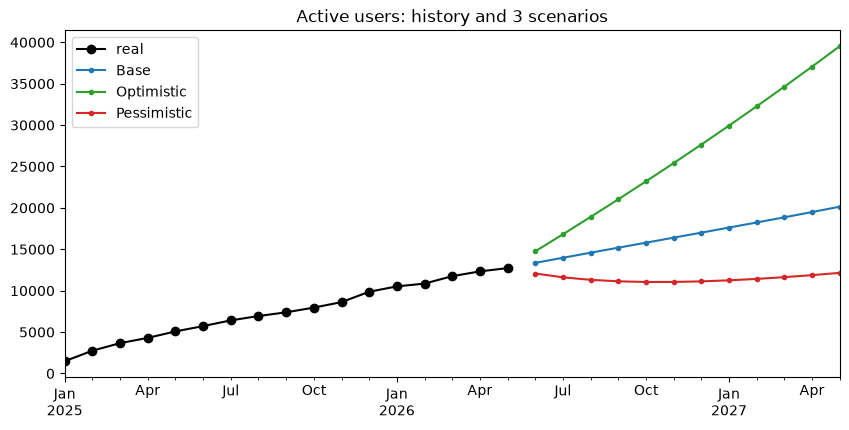

For K = 1 we need v of 0.85 invited signups per active user per month, today v = 0.48
The loop must be 1.8x stronger than today


In [54]:
colors = {"Base": "tab:blue", "Optimistic": "tab:green", "Pessimistic": "tab:red"}
plt.figure(figsize=(10, 4.5))
monthly.active.plot(label="real", color="black", marker="o")
for name, sim in results.items():
    sim.active.plot(label=name, color=colors[name], marker=".")
plt.title("Active users: history and 3 scenarios")
plt.legend()
plt.show()
# what would it take for K = 1?
need_v = p_now["churn"] / p_now["act_inv"]
print(f"For K = 1 we need v of {need_v:.2f} invited signups per active user per month, today v = {p_now['v']:.2f}")
print(f"The loop must be {need_v / p_now['v']:.1f}x stronger than today")

| | Base | Optimistic | Pessimistic |
|---|---|---|---|
| K per active user | 0.56 | 0.93 | 0.33 |
| Active base May 2027 | 20.1k (+58%) | 39.5k (x3.1) | 12.1k (-5%) |
| New users per month May 2027 | 14.7k | 25.9k | 8.9k |
| Share of new users from invites | 63% | 78% | 46% |
| 12 month cost | EUR 523k | EUR 733k | EUR 315k |
| Cost per new activated user | EUR 8.7 | EUR 7.4 | EUR 7.5 |
| **Cost per retained user (all channels)** | EUR 25.8 | EUR 24.5 | EUR 20.6 |
| Cost per retained paid user | EUR 13.5 | EUR 12.6 | EUR 16.5 |
| Cost per retained referred user | EUR 60.5 | EUR 39.6 | EUR 65.8 |
| LTV:CAC (optional, assumption) | 0.04 | 0.09 | 0.01 |

* Base: growth continues but it is driven by ads and organic. The loop adds, it does not sustain.
* Optimistic: K = 0.93, still below 1. For K = 1 the invitation intensity (v) must be about 1.8x today's.
* Pessimistic: the active base shrinks a little and paid users cost 22% more.
* The blended cost per retained user is LOWER in the pessimistic scenario only because there are fewer referrals, and referrals are the expensive ones. So this metric must be read together with the number of users and with the paid and referred costs.
* LTV:CAC stays far below 3 in all scenarios, even with the optimistic monetisation (4% paying EUR 3.50). The subscription alone does not justify paid acquisition.
* Levers: channel mix (shift reward budget to WhatsApp), onboarding (biggest leak), reward design (pay after real use), monetisation (a better price or paying share).
## 10. A/B test plan

Hypothesis: the opt-out auto SMS contact sync creates volume but low quality invites and hurts the rating. Making it opt-in (and paying the reward after the invitee's 2nd split) will reduce invites but keep or raise good invitees, and protect the rating.

| Item | Proposal |
|---|---|
| Randomisation | New user at onboarding, 50/50, stratified by country |
| Control | Contact sync ON by default (today) |
| Treatment | Contact sync OFF by default (explicit opt-in screen) |
| Primary metric | Share of new users who bring at least 1 activated invitee within 30 days |
| Secondary | Invites per user, accept rate, good invitees per 100 new users, reward euros per good invitee |
| Guardrails | 1 star share, uninstall rate in first 7 days, SMS complaints and opt-outs |
| Decision rule | Ship if the primary metric is not worse (margin 1 point) and guardrails improve |

In [55]:
from statistics import NormalDist

# baseline: share of users (cohorts Mar and Apr 2026) with at least one activated invitee
cohort_users = users[(users.signup_month >= pd.Period("2026-03")) & (users.signup_month <= LAST_COHORT)]
act_invitees = invited[invited.activated == 1]
baseline = cohort_users.user_id.isin(act_invitees.inviter_user_id).mean()
print("baseline share:", round(baseline, 4))

baseline share: 0.1543


In [56]:
def n_per_arm(p1, p2, alpha=0.05, power=0.80):
    za = NormalDist().inv_cdf(1 - alpha / 2)
    zb = NormalDist().inv_cdf(power)
    pbar = (p1 + p2) / 2
    n = (za * (2 * pbar * (1 - pbar)) ** 0.5 + zb * (p1 * (1 - p1) + p2 * (1 - p2)) ** 0.5) ** 2 / (p1 - p2) ** 2
    return int(np.ceil(n))

days = (pd.Timestamp("2026-04-30") - pd.Timestamp("2026-03-01")).days + 1
new_users_per_day = len(cohort_users) / days

rows = []
for mde in [0.005, 0.01, 0.02]:
    n = n_per_arm(baseline, baseline + mde)
    rows.append({"detectable effect (points)": mde * 100, "users per arm": n,
                 "days needed": np.ceil(2 * n / new_users_per_day) + 30})   # +30 days to observe the outcome
display(pd.DataFrame(rows))
print("new users per day:", round(new_users_per_day))

,detectable effect (points),users per arm,days needed
0,0.500,83021,568.000
1,1.000,21023,167.000
2,2.000,5388,65.000


new users per day: 309


## 11. Answer to the board

Is Splitly's viral coefficient really close to 1? No.

1. The "close to 1" comes from a shortcut (invites per inviter x acceptance = 1.14) that divides by the 38% of users who invite and counts duplicates, QA accounts and signups that never use the app.
2. Clean K per signup is 0.64 counting every invitee, 0.20 counting activated invitees and 0.05 counting good users. The bonus tripled the first number and did not improve the last one.
3. The loop is a booster, not an engine. Growth is still paid by ads and organic (about 40% of new users).

What went wrong:
* Value leaks in three places: acceptance after auto SMS (2.5%), invitee activation (62% to 30%) and 30 day retention of invitees (49% to 24%).
* A referred retained user costs 4 to 5 times more than a paid one (EUR 60 to 70 vs EUR 14), and 37% of the reward budget (EUR 61k) went to invitees who never made a split.
* The contact sync gave +140 good users per month but cost 0.9 stars of rating (4.43 to 3.54) and doubled the reviews.

Recommendations, in order:
1. Pay the reward only after real use (2nd split) and audit the 6k rewards without a split.
2. Make the contact sync opt-in (A/B test in section 10), cap auto SMS and push WhatsApp invites.
3. Fix onboarding for invitees and track good users per month as the North Star.
4. Define monetisation. Without revenue data we use the cost per retained user (paid EUR 13.5, referred EUR 60.5). With a stated assumption (2.5% of active users paying EUR 3 per month, similar to Splitwise Pro) LTV:CAC is only about 0.04, and it stays below 0.1 even in the optimistic scenario.

Limits: no revenue data (LTV is only an assumption, tested in the scenarios), no city data, before and after comparisons are not proof of causality, June 2026 was excluded, and model parameters use only 3 months. The scenario changes are general assumptions, not estimates from the data.


## 12. Export the clean data to Excel

In [57]:
# It reads the notebook variables (users, invites, rewards, spend, ratings, log) and writes ONE file: Splitly_clean_data.xlsx
OUT = DATA / "Splitly_clean_data.xlsx"

PERIOD_LABEL = {"1_before_referral": "1 Before bonus",      # same labels the Excel model uses
                "2_referral_bonus": "2 Bonus",
                "3_referral_plus_sync": "3 Bonus + sync"}

def first_of_month(s):                                       # real Excel date, 1st day of the month
    return s.dt.to_period("M").dt.to_timestamp()

#  Clean_Users: one row per user + helper columns the Excel formulas use
cu = users.copy()
cu["signup_month"] = first_of_month(cu.signup_date)
cu["period"] = cu.period.map(PERIOD_LABEL)
cu["obs_30"] = cu.obs_30.astype(int)                         # 1 = signed up 30+ days before extraction
cu["in_analysis"] = (cu.signup_date <= LAST_FULL).astype(int)  # 1 = signed up Jan-25..May-26 (June excluded)
cu["segment"] = np.where(cu.signup_date <= SEG_END, make_segment(cu), "")   # used by the retention curves
cu["inviter_cohort"] = cu.inviter_user_id.map(cu.set_index("user_id").signup_month)  # month the inviter signed up
cu = cu[["user_id", "signup_date", "signup_month", "period", "source", "inviter_user_id", "inviter_cohort",
         "country", "activated", "splits_first_30d", "last_active_date", "life_days", "retained_30",
         "good_user", "obs_30", "in_analysis", "segment"]]

# ---- Clean_Invites: one row per invite + what happened to the invitee
who = users[["user_id", "activated", "obs_30", "retained_30"]].rename(columns={
    "user_id": "invitee_user_id", "activated": "invitee_activated",
    "obs_30": "invitee_obs_30", "retained_30": "invitee_retained_30"})
ci = invites.merge(who, on="invitee_user_id", how="left")
assert len(ci) == len(invites), "merge duplicated invites"
ci["sent_month"] = first_of_month(ci.sent_date)
ci["period"] = ci.period.map(PERIOD_LABEL)
ci["invitee_obs_30"] = ci.invitee_obs_30.astype("Int64")     # blank when the invite was not accepted
ci["invitee_activated"] = ci.invitee_activated.astype("Int64")
ci["invitee_retained_30"] = ci.invitee_retained_30.astype("Int64")
ci["in_analysis"] = (ci.sent_date <= LAST_FULL).astype(int)
ci = ci[["invite_id", "inviter_user_id", "invitee_user_id", "sent_date", "sent_month", "period", "channel",
         "accepted", "invitee_activated", "invitee_obs_30", "invitee_retained_30", "in_analysis"]]

#  Clean_Rewards and Clean_Spend
cr = rewards.copy()
cr["paid_month"] = first_of_month(cr.paid_date)
cr = cr[["reward_id", "inviter_user_id", "invitee_user_id", "paid_date", "paid_month",
         "total_cost_eur", "invitee_activated"]]
cs = spend[["month", "channel", "spend_eur"]].copy()

# Data dictionary so the Excel is self-explaining
readme = pd.DataFrame([
    ("Clean_Users", "signup_month / inviter_cohort", "1st day of the month (real date). inviter_cohort = month the inviter signed up"),
    ("Clean_Users", "period", "1 Before bonus (to Oct-25) | 2 Bonus (Nov-25 to Feb-26) | 3 Bonus + sync (Mar-26 on)"),
    ("Clean_Users", "life_days / retained_30", "last_active_date - signup_date. retained_30 = 1 if life_days >= 30"),
    ("Clean_Users", "good_user", "1 = activated AND retained_30 = retained user (quality filter, used for the North Star)"),
    ("Clean_Users", "obs_30", "1 = signed up at least 30 days before extraction, so retention can be judged"),
    ("Clean_Users", "in_analysis", "1 = signed up on or before 2026-05-31. June 2026 is incomplete and excluded"),
    ("Clean_Users", "segment", "paid / organic / invite_before_bonus / invite_after_bonus, only users who signed up by 2025-12-31"),
    ("Clean_Invites", "invitee_*", "What happened to the accepted invitee. Blank when the invite was not accepted"),
    ("Clean_Invites", "channel", "whatsapp / sms / link / auto_sms_contact_sync (labels already unified)"),
    ("Clean_Rewards", "invitee_activated", "0 = reward was paid but the invitee never made a split (the leak)"),
    ("Clean_Spend", "spend_eur", "Paid acquisition only (the only channel in marketing_spend.csv)"),
], columns=["sheet", "column", "meaning"])

#  write (xlsxwriter is fast; pip install xlsxwriter if the import fails)
sheets = {"Clean_Users": cu, "Clean_Invites": ci, "Clean_Rewards": cr, "Clean_Spend": cs,
          "Clean_Ratings": ratings, "Cleaning_Log": log, "README": readme}
with pd.ExcelWriter(OUT, engine="xlsxwriter", datetime_format="yyyy-mm-dd", date_format="yyyy-mm-dd") as xw:
    for name, df in sheets.items():
        df.to_excel(xw, sheet_name=name, index=False)
        ws = xw.sheets[name]
        ws.freeze_panes(1, 0)
        ws.autofilter(0, 0, len(df), df.shape[1] - 1)
        ws.set_column(0, df.shape[1] - 1, 16)
for name, df in sheets.items():
    print(f"{name:14s} {len(df):>8,} rows  {df.shape[1]} columns")
print("saved:", OUT)

Clean_Users      95,766 rows  17 columns
Clean_Invites   198,789 rows  12 columns
Clean_Rewards    16,533 rows  7 columns
Clean_Spend          18 rows  3 columns
Clean_Ratings        18 rows  4 columns
Cleaning_Log         23 rows  5 columns
README               11 rows  3 columns
saved: ..\data\Splitly_clean_data.xlsx


### 12.1 Data for the Excel growth simulator

The sheet `Splitly_Data` of the simulator (Splitly_Growth_Model_Simulator.xlsx) needs the monthly table. This file has the same columns in the same order: copy it into `Splitly_Data!B5:M21`.

In [58]:
sd = monthly[["paid_new", "paid_act", "paid_ret", "organic_new", "organic_act", "organic_ret",
              "invite_new", "invite_act", "invite_ret", "spend", "reward_eur", "active"]].copy()
sd.index = sd.index.to_timestamp()
sd.index.name = "Month"
sd.columns = ["Paid signups", "Paid activated", "Paid retained D30", "Organic signups", "Organic activated", "Organic retained D30",
              "Invited signups", "Invited activated", "Invited retained D30", "Ad spend (EUR)", "Reward cost (EUR)", "Active base"]
sd.to_csv(DATA / "Splitly_Data_for_simulator.csv")
print("saved:", DATA / "Splitly_Data_for_simulator.csv")
sd.tail(3)

saved: ..\data\Splitly_Data_for_simulator.csv


,Paid signups,Paid activated,Paid retained D30,Organic signups,Organic activated,Organic retained D30,Invited signups,Invited activated,Invited retained D30,Ad spend (EUR),Reward cost (EUR),Active base
Month,,,,,,,,,,,,
2026-03-01,1890,1029,440,1663,941,402,5648,1742,429,"6,050.000","26,200.000",11751
2026-04-01,1946,1124,477,1713,905,414,5979,1854,450,"6,230.000","28,790.000",12330
2026-05-01,2006,1095,467,1765,1021,428,4928,1721,396,"6,420.000","22,190.000",12724
